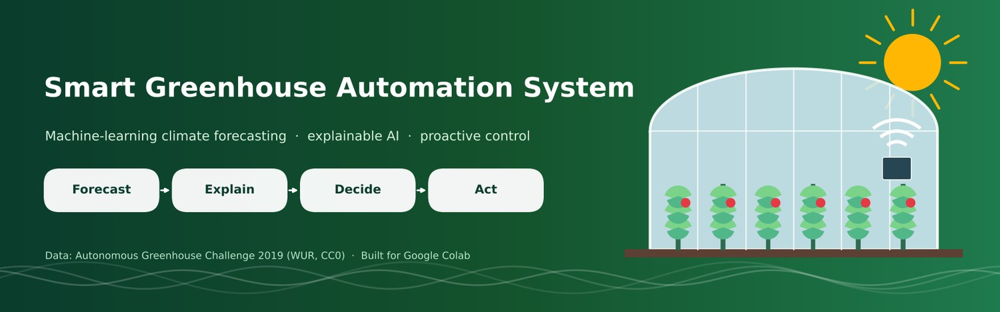

# Smart Greenhouse Automation System
### Forecasting greenhouse climate with machine learning, explaining it, and turning it into control actions

| | |
|---|---|
| **Goal** | Predict air temperature and relative humidity **30 and 60 minutes ahead**, then decide on ventilation, heating and irrigation *before* conditions go out of range |
| **Data** | Autonomous Greenhouse Challenge, 2nd edition (Wageningen University & Research, 2019–20), 5-minute sensor data, licence CC0 |
| **Primary paper** | Hindi et al., *PLOS ONE* 21(3): e0344946 (2026) |
| **Dataset paper** | Hemming et al., *Sensors* 20(22): 6430 (2020) |
| **Runs on** | Google Colab, free tier. `Runtime → Run all`. A T4 GPU is optional and speeds up the LSTM and GRU models |

**What makes this notebook different from typical student greenhouse projects**

1. **Honest evaluation:** a time-ordered split (no future leakage) and every model scored against a "no change" baseline.
2. **Accuracy you can quote:** Accuracy % (100 − mean percentage error), R², RMSE, MAE, the share of forecasts within ±1 °C / ±5 % RH, and decision accuracy for the controller.
3. **Eight models under one protocol:** Ridge, Random Forest, XGBoost, LightGBM, tuned LightGBM, LSTM, GRU and an ensemble chosen on validation data.
4. **Uncertainty:** 80 % prediction intervals from quantile regression, calibrated with conformal prediction so they really cover about 80 %.
5. **Explainability:** SHAP explanations for the whole model and for a single forecast.
6. **Control impact:** proactive (forecast-based) control compared with a reactive thermostat, including **early-warning lead time**.
7. **Research lab:** forecast-horizon curve, sensor ablation, cheap-sensor robustness, learning curve, an AI "what-if" controller and an animated live replay.
8. **Deployment-ready:** a `predict_from_sensors()` function that takes an IoT JSON payload and returns forecasts, actions and reasons.

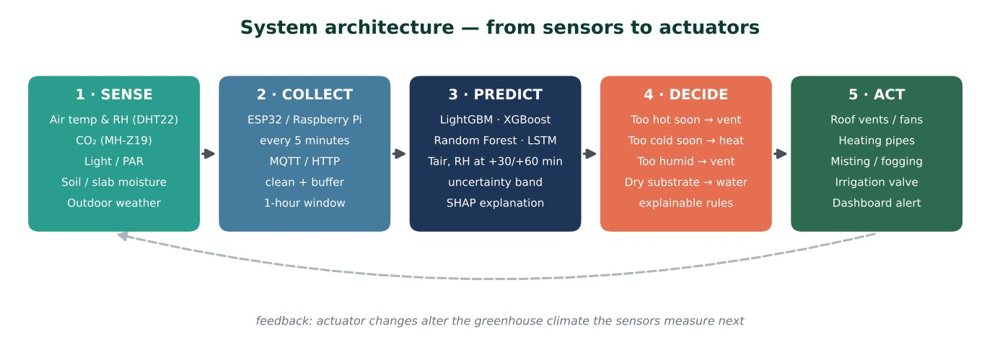

## Contents
1. Setup · 2. Configuration · 3. Data · 4. Load & merge · 5. **Know your greenhouse (EDA)** · 6. Cleaning · 7. Feature engineering · 8. Time-ordered split ·
9. Classic ML · 10. Hyper-parameter tuning · 11. Deep learning · 12. Ensemble · 13. **Uncertainty** · 14. **Leaderboard** · 15. Error analysis ·
16. Forecast showcase · 17. **Explainable AI** · 18. **Proactive control** · 19. **Live dashboard** · 20. **IoT inference API** · 21. **Research lab (A–F)** · 22. Generalisation test ·
23. Save everything · 24. Auto-generated summary · 25. References

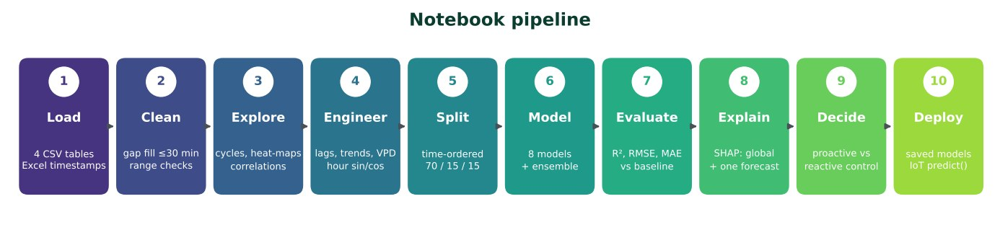

## 1 · Setup

In [1]:
!pip -q install xgboost lightgbm shap optuna plotly

import os, glob, json, time, warnings, textwrap
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch
from IPython.display import display, Markdown, HTML

SEED = 42
np.random.seed(SEED)
NOTEBOOK_START = time.time()

# ---------- one visual identity for every chart ----------
PALETTE = {"Persistence": "#adb5bd", "Ridge": "#8d99ae", "RandomForest": "#2a9d8f", "XGBoost": "#e76f51",
           "LightGBM": "#264653", "LightGBM-tuned": "#1d3557", "LSTM": "#9b5de5", "GRU": "#f15bb5",
           "Ensemble": "#ffb703"}
C = dict(dark="#0b3d2e", green="#2d6a4f", teal="#2a9d8f", blue="#1d3557", orange="#e76f51",
         red="#d62828", yellow="#ffb703", grey="#6c757d", light="#e9ecef")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "figure.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25,
    "axes.titleweight": "bold", "axes.titlesize": 12.5, "axes.titlecolor": C["dark"], "axes.labelcolor": "#333",
    "font.size": 10.5, "legend.frameon": False,
})

FIG_DIR = "outputs/figures"
os.makedirs(FIG_DIR, exist_ok=True)
def save(fig, name):
    fig.savefig(os.path.join(FIG_DIR, f"{name}.png"), bbox_inches="tight")

def section_banner(text, color=C["dark"]):
    display(HTML(f'<div style="background:{color};color:white;padding:10px 16px;border-radius:8px;'
                 f'font-size:15px;font-weight:600;margin:6px 0">{text}</div>'))

section_banner(f"Environment ready · pandas {pd.__version__} · numpy {np.__version__}")

## 2 · Configuration
Every adjustable choice lives here. The decision thresholds are agronomic choices: justify them in your report, or adapt them to your crop.

In [2]:
CFG = dict(
    TEAM          = "AICU",          # greenhouse compartment for the main experiment
    HORIZONS_MIN  = [30, 60],        # forecast horizons (minutes)
    STEP_MIN      = 5,               # sensor resolution (minutes)
    TARGETS       = ["Tair", "Rhair"],
    LAGS          = [1, 2, 3, 6, 12],  # lag steps (×5 min)
    TRAIN_FRAC    = 0.70, VAL_FRAC = 0.15,   # test = last 15 %
    MAX_GAP_STEPS = 6,               # interpolate gaps ≤ 30 min
    SEQ_LEN       = 12,              # LSTM/GRU look-back (12 × 5 min = 1 h)
    EPOCHS        = 30, BATCH = 256,
    TUNE_TRIALS   = 25,              # Optuna trials for LightGBM tuning (0 = skip)
    INTERVAL      = (0.10, 0.90),    # quantiles → 80 % prediction interval
    # decision layer
    VENT_T = 25.0,                   # ventilate if Tair will exceed (°C)
    HEAT_T = 18.0,                   # heat if Tair will drop below (°C)
    RH_HIGH = 90.0,                  # ventilate/dehumidify if RH will exceed (%)
    OUT_DIR = "outputs",
)
os.makedirs(CFG["OUT_DIR"], exist_ok=True)
pd.Series(CFG).to_frame("value")

,value
TEAM,AICU
HORIZONS_MIN,"[30, 60]"
STEP_MIN,5
TARGETS,"[Tair, Rhair]"
LAGS,"[1, 2, 3, 6, 12]"
TRAIN_FRAC,0.7
VAL_FRAC,0.15
MAX_GAP_STEPS,6
SEQ_LEN,12
EPOCHS,30


## 3 · Data
**Option A (default, no login):** clone a public GitHub copy of the AICU compartment and the outdoor weather from the AGC 2nd edition.

**Option B (all 6 compartments):** download the dataset from [4TU.ResearchData](https://doi.org/10.4121/uuid:88d22c60-21b3-4ea8-90db-20249a5be2a7), unzip it to Google Drive, set `USE_DRIVE = True` and point `DRIVE_DATA_DIR` at the folder. Option B also unlocks the *unseen-greenhouse* test in Section 21. The `AGC2019_AICU_subset.zip` supplied with this project works here too.

| Variable | Meaning | Unit |
|---|---|---|
| `Tair`, `Rhair`, `CO2air` | Indoor air temperature, relative humidity, CO₂ | °C, %, ppm |
| `HumDef` | Humidity deficit | g/m³ |
| `Tot_PAR`, `Tot_PAR_Lamps` | Light for photosynthesis (total / from lamps) | µmol/m²/s |
| `PipeGrow`, `PipeLow` | Heating-pipe temperatures | °C |
| `VentLee`, `Ventwind` | Roof-vent opening (lee / wind side) | % |
| `BlackScr`, `EnScr` | Blackout and energy screen closure | % |
| `WC_slab1/2` | Substrate (root-zone) water content | % |
| `Tout`, `Rhout`, `Iglob`, `Windsp` | Outdoor temperature, RH, global radiation, wind speed | °C, %, W/m², m/s |

**Where the numbers come from.** The Wageningen glasshouse uses professional climate boxes. The cards show low-cost sensors that measure the same quantities, which is what you would install in a real Indian polyhouse.

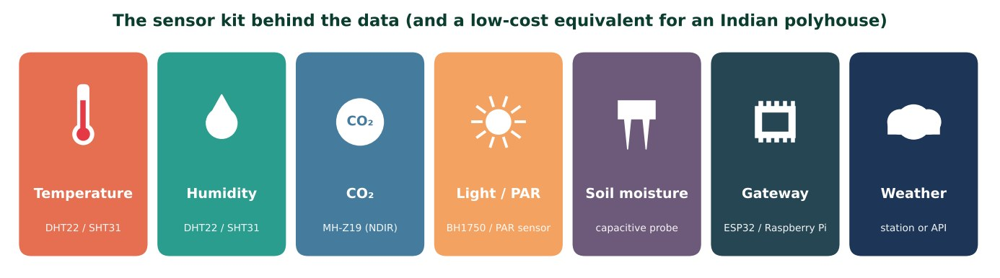

In [3]:
USE_DRIVE = False
DRIVE_DATA_DIR = "/content/drive/MyDrive/AGC2019"

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR = DRIVE_DATA_DIR
else:
    if not os.path.exists("agc_mirror"):
        !git clone -q --depth 1 https://github.com/masoudgheisari92/greenhouse-temperature-prediction.git agc_mirror
    DATA_DIR = "agc_mirror/data"

climate_files = sorted(glob.glob(os.path.join(DATA_DIR, "**", "GreenhouseClimate.csv"), recursive=True))
TEAMS = {os.path.basename(os.path.dirname(p)): os.path.dirname(p) for p in climate_files}
weather_files = glob.glob(os.path.join(DATA_DIR, "**", "Weather.csv"), recursive=True)
assert TEAMS and weather_files, f"Dataset files not found under {DATA_DIR}"
WEATHER_FILE = weather_files[0]
if CFG["TEAM"] not in TEAMS:
    CFG["TEAM"] = list(TEAMS)[0]
section_banner(f"Compartments found: {', '.join(TEAMS)} · main experiment on {CFG['TEAM']}")

## 4 · Load and merge
The `%time` column is an **Excel serial date** (43815 = 16 Dec 2019). It is converted, snapped to the 5-minute grid, and the indoor-climate, substrate and outdoor-weather tables are joined on it.

In [4]:
def excel_to_datetime(x):
    return pd.to_datetime("1899-12-30") + pd.to_timedelta(pd.to_numeric(x, errors="coerce"), unit="D")

def read_agc(path):
    df = pd.read_csv(path, skipinitialspace=True, na_values=["NaN", "nan", ""])
    df.columns = [c.strip() for c in df.columns]
    tcol = [c for c in df.columns if c.lower().lstrip("%").strip() == "time"][0]
    df["timestamp"] = excel_to_datetime(df[tcol]).dt.round(f"{CFG['STEP_MIN']}min")
    df = df.drop(columns=[tcol] + [c for c in ["dt"] if c in df.columns])
    for c in df.columns:
        if c != "timestamp":
            df[c] = pd.to_numeric(df[c], errors="coerce")
    return df.groupby("timestamp").mean()

WEATHER = read_agc(WEATHER_FILE).add_suffix("_out")

def load_team(team):
    folder = TEAMS[team]
    df = read_agc(os.path.join(folder, "GreenhouseClimate.csv"))
    slab = os.path.join(folder, "GrodanSens.csv")
    if os.path.exists(slab):
        df = df.join(read_agc(slab), how="left")
    df = df.join(WEATHER, how="left")
    return df.reindex(pd.date_range(df.index.min(), df.index.max(), freq=f"{CFG['STEP_MIN']}min"))

raw = load_team(CFG["TEAM"])
section_banner(f"{len(raw):,} time steps × {raw.shape[1]} signals · {raw.index.min():%d %b %Y} → {raw.index.max():%d %b %Y}")
raw[["Tair", "Rhair", "CO2air", "Tot_PAR", "Tout_out", "Rhout_out", "Iglob_out"]].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Tair,47738.0,22.06,2.99,11.9,19.9,21.6,23.90,31.1
Rhair,47738.0,84.17,9.14,37.6,79.6,87.1,90.30,97.5
CO2air,47738.0,765.43,191.93,379.0,614.0,760.0,880.00,2000.0
Tot_PAR,47738.0,201.37,206.67,0.0,0.0,197.0,261.00,1004.0
Tout_out,47738.0,9.03,4.23,-0.2,6.3,8.4,11.00,27.3
Rhout_out,47738.0,74.85,19.87,10.1,61.7,79.3,91.28,99.7
Iglob_out,47738.0,125.30,222.01,0.0,0.0,0.0,146.00,1505.0


## 5 · Know your greenhouse: exploratory analysis
Before modelling, understand the system: the seasonal trend, the daily rhythm, and which signals move together.

### 5.1 The whole season at a glance

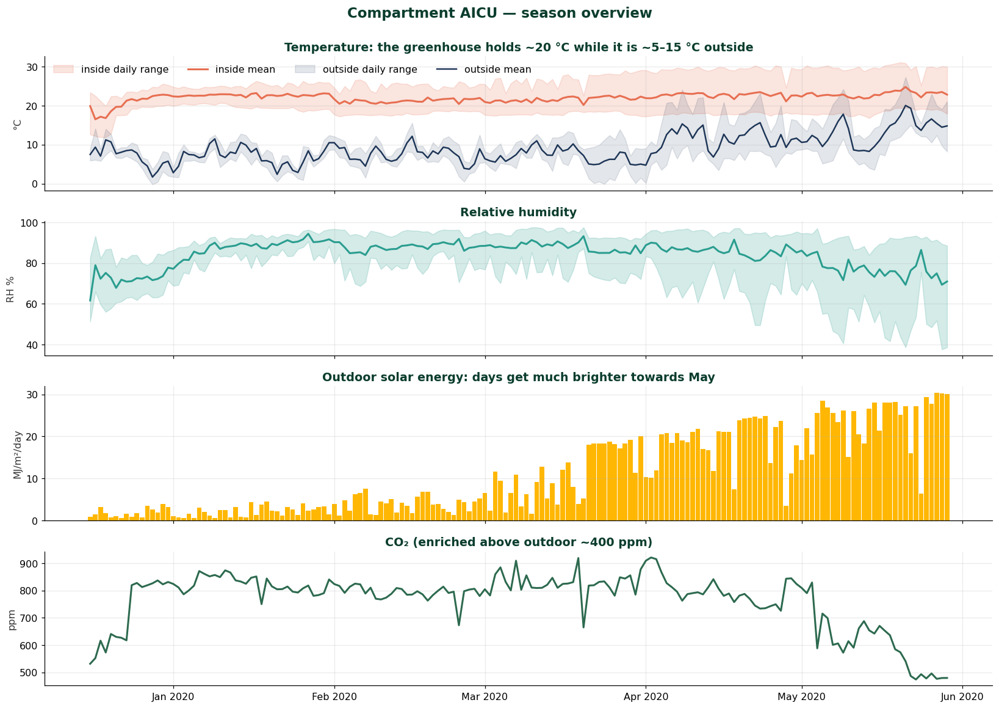

In [5]:
daily = raw.resample("D").agg(["mean", "min", "max"])
fig, axes = plt.subplots(4, 1, figsize=(15, 10.5), sharex=True)
ax = axes[0]
ax.fill_between(daily.index, daily[("Tair", "min")], daily[("Tair", "max")], color=C["orange"], alpha=0.18, label="inside daily range")
ax.plot(daily.index, daily[("Tair", "mean")], color=C["orange"], lw=2, label="inside mean")
ax.fill_between(daily.index, daily[("Tout_out", "min")], daily[("Tout_out", "max")], color=C["blue"], alpha=0.12, label="outside daily range")
ax.plot(daily.index, daily[("Tout_out", "mean")], color=C["blue"], lw=1.6, label="outside mean")
ax.set_ylabel("°C"); ax.set_title("Temperature: the greenhouse holds ~20 °C while it is ~5–15 °C outside"); ax.legend(ncol=4, loc="upper left")
ax = axes[1]
ax.fill_between(daily.index, daily[("Rhair", "min")], daily[("Rhair", "max")], color=C["teal"], alpha=0.2)
ax.plot(daily.index, daily[("Rhair", "mean")], color=C["teal"], lw=2); ax.set_ylabel("RH %"); ax.set_title("Relative humidity")
ax = axes[2]
ax.bar(daily.index, daily[("Iglob_out", "mean")] * 24 * 3600 / 1e6, color=C["yellow"], width=0.9)
ax.set_ylabel("MJ/m²/day"); ax.set_title("Outdoor solar energy: days get much brighter towards May")
ax = axes[3]
ax.plot(daily.index, daily[("CO2air", "mean")], color=C["green"], lw=2); ax.set_ylabel("ppm"); ax.set_title("CO₂ (enriched above outdoor ~400 ppm)")
axes[3].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
fig.suptitle(f"Compartment {CFG['TEAM']} — season overview", fontsize=15, weight="bold", color=C["dark"], y=1.0)
fig.tight_layout(); save(fig, "01_season_overview"); plt.show()

### 5.2 Climate fingerprint: hour × day heat-maps

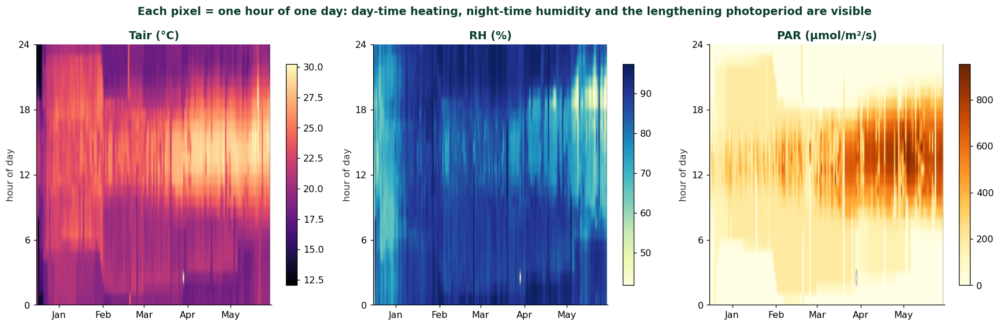

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.2))
for ax, (col, cmap, lab) in zip(axes, [("Tair", "magma", "Tair (°C)"), ("Rhair", "YlGnBu", "RH (%)"), ("Tot_PAR", "YlOrBr", "PAR (µmol/m²/s)")]):
    hm = raw[col].groupby([raw.index.date, raw.index.hour]).mean().unstack()
    im = ax.imshow(hm.T.values, aspect="auto", cmap=cmap, origin="lower",
                   extent=[mdates.date2num(pd.Timestamp(hm.index[0])), mdates.date2num(pd.Timestamp(hm.index[-1])), 0, 24])
    ax.xaxis_date(); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b")); ax.set_yticks(range(0, 25, 6))
    ax.set_ylabel("hour of day"); ax.set_title(lab); ax.grid(False)
    fig.colorbar(im, ax=ax, shrink=0.85)
fig.suptitle("Each pixel = one hour of one day: day-time heating, night-time humidity and the lengthening photoperiod are visible", fontsize=12.5, color=C["dark"], weight="bold")
fig.tight_layout(); save(fig, "02_fingerprint_heatmaps"); plt.show()

### 5.3 The average day, month by month

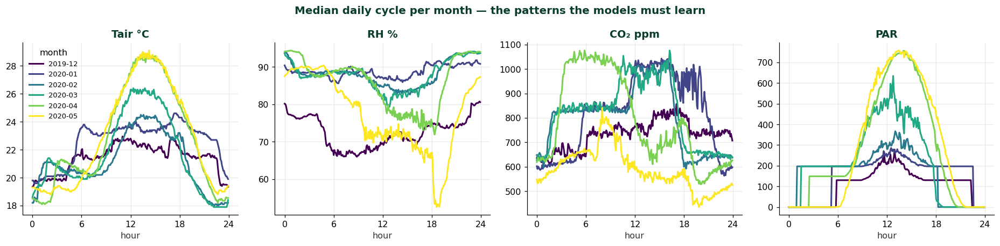

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2))
months = sorted(set(raw.index.to_period("M")))
cmap = plt.get_cmap("viridis", len(months))
for ax, (col, lab) in zip(axes, [("Tair", "Tair °C"), ("Rhair", "RH %"), ("CO2air", "CO₂ ppm"), ("Tot_PAR", "PAR")]):
    for k, m in enumerate(months):
        sub = raw.loc[raw.index.to_period("M") == m, col]
        prof = sub.groupby(sub.index.hour + sub.index.minute / 60).median()
        ax.plot(prof.index, prof.values, color=cmap(k), lw=2, label=str(m))
    ax.set_xticks([0, 6, 12, 18, 24]); ax.set_xlabel("hour"); ax.set_title(lab)
axes[0].legend(title="month", fontsize=8.5)
fig.suptitle("Median daily cycle per month — the patterns the models must learn", fontsize=13, weight="bold", color=C["dark"])
fig.tight_layout(); save(fig, "03_daily_cycles"); plt.show()

### 5.4 Which signals move together?

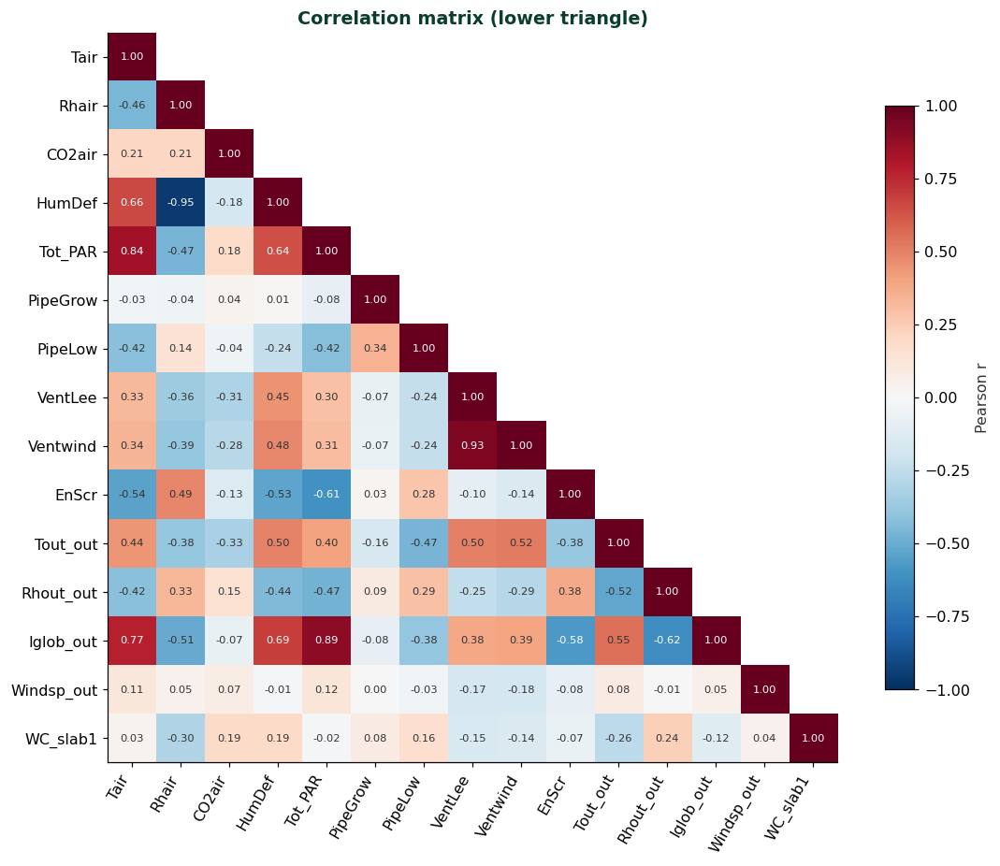

In [8]:
key = ["Tair", "Rhair", "CO2air", "HumDef", "Tot_PAR", "PipeGrow", "PipeLow", "VentLee", "Ventwind",
       "EnScr", "Tout_out", "Rhout_out", "Iglob_out", "Windsp_out", "WC_slab1"]
key = [k for k in key if k in raw]
corr = raw[key].corr()
fig, ax = plt.subplots(figsize=(10.5, 8.5))
mask = np.triu(np.ones_like(corr, dtype=bool), 1)
im = ax.imshow(np.ma.masked_where(mask, corr), cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(key))); ax.set_xticklabels(key, rotation=60, ha="right"); ax.set_yticks(range(len(key))); ax.set_yticklabels(key)
for i in range(len(key)):
    for j in range(i + 1):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7.5, color="white" if abs(v) > 0.55 else "#333")
ax.grid(False); fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson r")
ax.set_title("Correlation matrix (lower triangle)")
fig.tight_layout(); save(fig, "04_correlations"); plt.show()

### 5.5 Distributions of the key signals
Histograms with day (sun up) and night shown separately: night air is cooler and more humid, so a single average would hide two regimes.

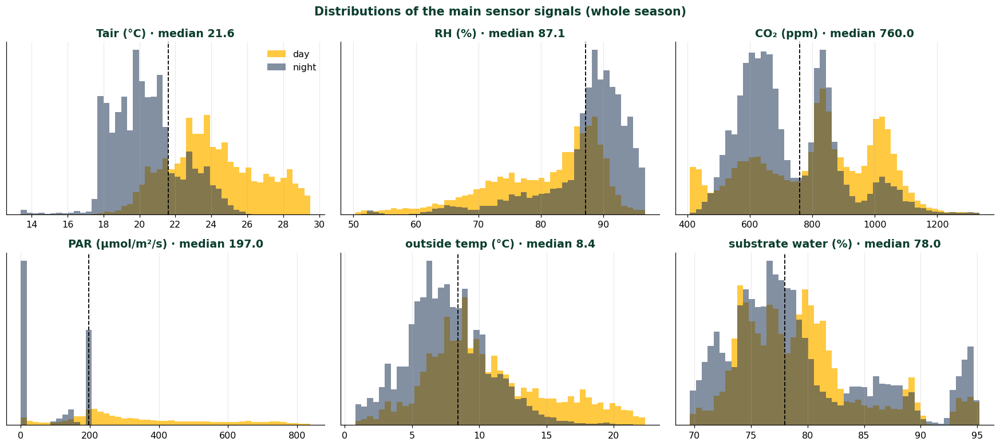

In [9]:
cols = [("Tair", "Tair (°C)"), ("Rhair", "RH (%)"), ("CO2air", "CO₂ (ppm)"), ("Tot_PAR", "PAR (µmol/m²/s)"),
        ("Tout_out", "outside temp (°C)"), ("WC_slab1", "substrate water (%)")]
cols = [c for c in cols if c[0] in raw]
is_day = raw["Iglob_out"] > 5
fig, axes = plt.subplots(2, 3, figsize=(16, 7.2))
for ax, (c, lab) in zip(axes.flat, cols):
    v = raw[c].dropna(); bins = np.linspace(v.quantile(0.005), v.quantile(0.995), 50)
    ax.hist(raw.loc[is_day, c].dropna(), bins=bins, color=C["yellow"], alpha=0.75, label="day")
    ax.hist(raw.loc[~is_day, c].dropna(), bins=bins, color=C["blue"], alpha=0.55, label="night")
    ax.axvline(v.median(), color="black", lw=1.2, ls="--"); ax.set_title(f"{lab} · median {v.median():.1f}"); ax.set_yticks([])
axes.flat[0].legend()
fig.suptitle("Distributions of the main sensor signals (whole season)", fontsize=13.5, weight="bold", color=C["dark"])
fig.tight_layout(); save(fig, "04b_distributions"); plt.show()

### 5.6 How the climate computer reacts

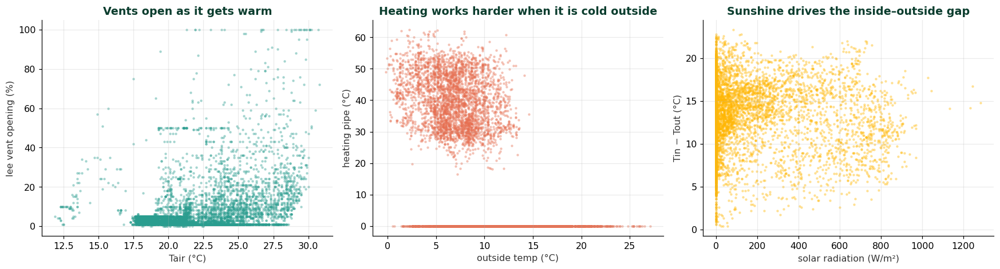

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
s = raw.sample(8000, random_state=SEED)
axes[0].scatter(s["Tair"], s["VentLee"], s=4, alpha=0.3, color=C["teal"]); axes[0].set_xlabel("Tair (°C)"); axes[0].set_ylabel("lee vent opening (%)")
axes[0].set_title("Vents open as it gets warm")
axes[1].scatter(s["Tout_out"], s["PipeLow"], s=4, alpha=0.3, color=C["orange"]); axes[1].set_xlabel("outside temp (°C)"); axes[1].set_ylabel("heating pipe (°C)")
axes[1].set_title("Heating works harder when it is cold outside")
axes[2].scatter(s["Iglob_out"], s["Tair"] - s["Tout_out"], s=4, alpha=0.3, color=C["yellow"]); axes[2].set_xlabel("solar radiation (W/m²)"); axes[2].set_ylabel("Tin − Tout (°C)")
axes[2].set_title("Sunshine drives the inside–outside gap")
fig.tight_layout(); save(fig, "05_control_behaviour"); plt.show()

## 6 · Cleaning
Keep signals that are at least 80 % present, remove physically impossible values, and interpolate gaps of 30 minutes or less (longer gaps stay missing and are dropped later).

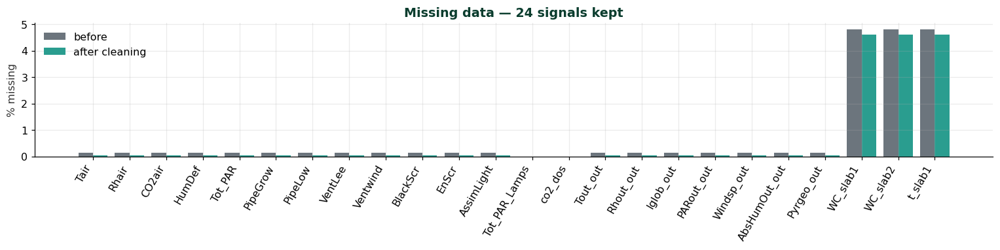

In [11]:
INDOOR    = ["Tair", "Rhair", "CO2air", "HumDef", "Tot_PAR"]
ACTUATORS = ["PipeGrow", "PipeLow", "VentLee", "Ventwind", "BlackScr", "EnScr", "AssimLight", "Tot_PAR_Lamps", "co2_dos"]
OUTDOOR   = ["Tout_out", "Rhout_out", "Iglob_out", "PARout_out", "Windsp_out", "AbsHumOut_out", "Pyrgeo_out"]
SLAB      = ["WC_slab1", "WC_slab2", "t_slab1"]

def clean(df):
    cols = [c for c in INDOOR + ACTUATORS + OUTDOOR + SLAB if c in df.columns and df[c].notna().mean() > 0.8]
    d = df[cols].copy()
    limits = {"Tair": (0, 50), "Rhair": (0, 100), "CO2air": (200, 3000), "Tout_out": (-30, 50), "Rhout_out": (0, 100)}
    for c, (lo, hi) in limits.items():
        if c in d: d.loc[(d[c] < lo) | (d[c] > hi), c] = np.nan
    return d.interpolate(method="time", limit=CFG["MAX_GAP_STEPS"], limit_area="inside")

data = clean(raw)
miss_before = raw[data.columns].isna().mean() * 100
miss_after = data.isna().mean() * 100
fig, ax = plt.subplots(figsize=(14, 3.6))
x = np.arange(len(data.columns))
ax.bar(x - 0.2, miss_before, 0.4, color=C["grey"], label="before"); ax.bar(x + 0.2, miss_after, 0.4, color=C["teal"], label="after cleaning")
ax.set_xticks(x); ax.set_xticklabels(data.columns, rotation=60, ha="right"); ax.set_ylabel("% missing"); ax.legend()
ax.set_title(f"Missing data — {len(data.columns)} signals kept")
fig.tight_layout(); save(fig, "06_missing_data"); plt.show()

## 7 · Feature engineering


The model sees the **last hour** and predicts the value **30 or 60 minutes later**. It learns the **change** `y(t+h) − y(t)`, and the current value is added back afterwards. This is easier to learn and makes the comparison with the *persistence* baseline ("nothing changes") fair.

Features per time step: current values, lags (5–60 min), 1-hour rolling mean, short-term trends, vapour-pressure deficit, the inside–outside temperature gap, and time of day (sine/cosine). Day-of-year is **deliberately excluded**: the test weeks fall in a season the training data never covers, so a model would have to guess outside its experience.


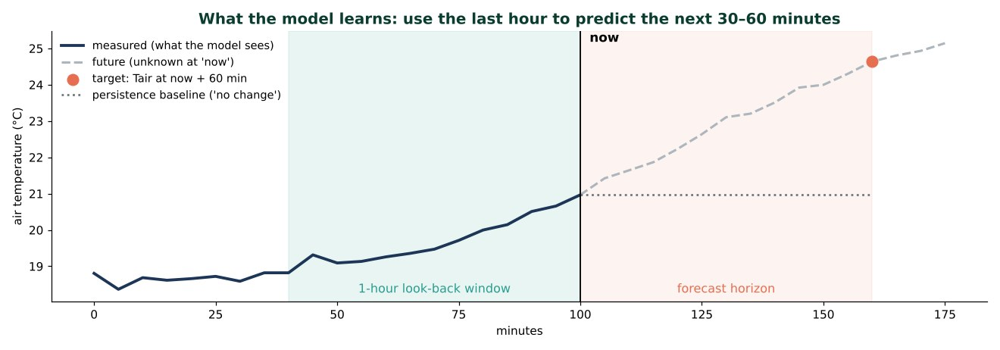

In [12]:
def make_features(d):
    X = pd.DataFrame(index=d.index)
    for c in d.columns:
        X[c] = d[c]
    for c in [c for c in INDOOR if c in d.columns]:
        for L in CFG["LAGS"]:
            X[f"{c}_lag{L}"] = d[c].shift(L)
        X[f"{c}_roll12_mean"] = d[c].rolling(12).mean()
        X[f"{c}_diff1"] = d[c].diff(1)
        X[f"{c}_diff6"] = d[c].diff(6)
    if "Tout_out" in d.columns:
        X["Tin_minus_Tout"] = d["Tair"] - d["Tout_out"]
        X["Tout_out_diff6"] = d["Tout_out"].diff(6)
    if "Iglob_out" in d.columns:
        X["Iglob_out_diff6"] = d["Iglob_out"].diff(6)
    es = 0.6108 * np.exp(17.27 * d["Tair"] / (d["Tair"] + 237.3))
    X["VPD_kPa"] = es * (1 - d["Rhair"] / 100)
    hour = d.index.hour + d.index.minute / 60
    X["hour_sin"], X["hour_cos"] = np.sin(2 * np.pi * hour / 24), np.cos(2 * np.pi * hour / 24)
    return X

def make_targets(d):
    return pd.DataFrame({f"{t}_t+{h}": d[t].shift(-h // CFG["STEP_MIN"])
                         for t in CFG["TARGETS"] for h in CFG["HORIZONS_MIN"]}, index=d.index)

X_all, Y_all = make_features(data), make_targets(data)
ok = X_all.notna().all(axis=1) & Y_all.notna().all(axis=1)
X_all, Y_all = X_all[ok], Y_all[ok]
FEATURES, TARGET_COLS = list(X_all.columns), list(Y_all.columns)
UNIT = {"Tair": "°C", "Rhair": "% RH"}
TOL = {"Tair": 1.0, "Rhair": 5.0}
section_banner(f"{len(X_all):,} training-ready samples · {len(FEATURES)} features · {len(TARGET_COLS)} targets: {', '.join(TARGET_COLS)}")

## 8 · Time-ordered split
Train on the past, tune on the following weeks, and test on the final weeks only once. Nothing is shuffled.

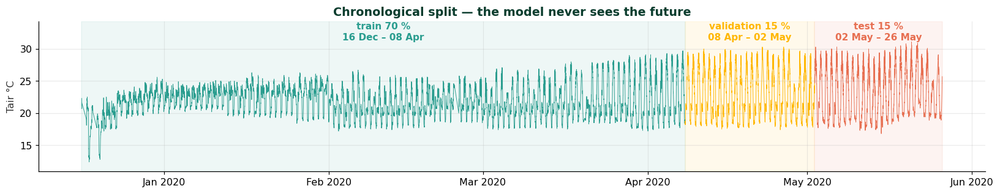

In [13]:
n = len(X_all)
i_tr, i_va = int(n * CFG["TRAIN_FRAC"]), int(n * (CFG["TRAIN_FRAC"] + CFG["VAL_FRAC"]))
idx_tr, idx_va, idx_te = X_all.index[:i_tr], X_all.index[i_tr:i_va], X_all.index[i_va:]
X_tr, X_va, X_te = X_all.loc[idx_tr], X_all.loc[idx_va], X_all.loc[idx_te]

fig, ax = plt.subplots(figsize=(15, 3))
for ix, col, lab in [(idx_tr, C["teal"], "train 70 %"), (idx_va, C["yellow"], "validation 15 %"), (idx_te, C["orange"], "test 15 %")]:
    ax.plot(ix, data.loc[ix, "Tair"], color=col, lw=0.6)
    ax.axvspan(ix.min(), ix.max(), color=col, alpha=0.08)
    ax.text(ix.min() + (ix.max() - ix.min()) / 2, data["Tair"].max() + 0.3, f"{lab}\n{ix.min():%d %b} – {ix.max():%d %b}",
            ha="center", fontsize=10, weight="bold", color=col)
ax.set_ylabel("Tair °C"); ax.set_ylim(data["Tair"].min() - 1, data["Tair"].max() + 3.2)
ax.set_title("Chronological split — the model never sees the future")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
fig.tight_layout(); save(fig, "07_split"); plt.show()

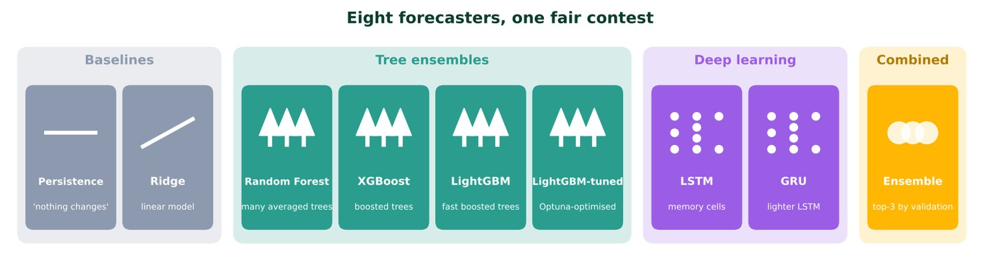

## 9 · Classic machine learning
One model per target and horizon. XGBoost and LightGBM use the validation set for early stopping. Predictions are stored for **validation and test**: the validation scores choose the ensemble members, and the test scores are reported.

In [14]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import xgboost as xgb
import lightgbm as lgb

PRED = {"val": {}, "test": {}}     # PRED[split][(target_col, model)] = pd.Series
FITTED, TRAIN_TIME = {}, {}

def tgt_of(col): return col.split("_t+")[0]
def delta(ix, col): return Y_all.loc[ix, col] - X_all.loc[ix, tgt_of(col)]

def classic_models():
    return {
        "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
        "RandomForest": RandomForestRegressor(n_estimators=200, max_depth=16, min_samples_leaf=5, max_features=0.5,
                                              n_jobs=-1, random_state=SEED),
        "XGBoost": xgb.XGBRegressor(n_estimators=2000, learning_rate=0.03, max_depth=6, subsample=0.8, colsample_bytree=0.8,
                                    early_stopping_rounds=100, random_state=SEED, n_jobs=-1),
        "LightGBM": lgb.LGBMRegressor(n_estimators=2000, learning_rate=0.03, num_leaves=63, subsample=0.8, subsample_freq=1,
                                      colsample_bytree=0.8, random_state=SEED, n_jobs=-1, verbose=-1),
    }

def fit_tree(name, model, col):
    y_tr, y_va = delta(idx_tr, col), delta(idx_va, col)
    if name.startswith("XGBoost"):
        model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
    elif name.startswith("LightGBM"):
        model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], callbacks=[lgb.early_stopping(100, verbose=False)])
    else:
        model.fit(X_tr, y_tr)
    return model

for col in TARGET_COLS:
    t = tgt_of(col)
    PRED["val"][(col, "Persistence")] = X_va[t]
    PRED["test"][(col, "Persistence")] = X_te[t]
    for name, model in classic_models().items():
        t0 = time.time()
        model = fit_tree(name, model, col)
        TRAIN_TIME[(col, name)] = time.time() - t0
        FITTED[(col, name)] = model
        PRED["val"][(col, name)] = X_va[t] + model.predict(X_va)
        PRED["test"][(col, name)] = X_te[t] + model.predict(X_te)
    print(f"✓ {col:11s} " + "  ".join(f"{m}: {TRAIN_TIME[(col, m)]:.1f}s" for m in classic_models()))

✓ Tair_t+30   Ridge: 0.1s  RandomForest: 104.0s  XGBoost: 12.0s  LightGBM: 8.2s
✓ Tair_t+60   Ridge: 0.1s  RandomForest: 100.2s  XGBoost: 13.3s  LightGBM: 14.4s
✓ Rhair_t+30  Ridge: 0.1s  RandomForest: 115.0s  XGBoost: 5.4s  LightGBM: 3.5s
✓ Rhair_t+60  Ridge: 0.1s  RandomForest: 101.6s  XGBoost: 7.8s  LightGBM: 3.6s


## 10 · Hyper-parameter tuning with Optuna
Optuna's Bayesian search tunes LightGBM on the **validation** set for the hardest temperature target (60 min). The best settings are then reused for every target as `LightGBM-tuned`.

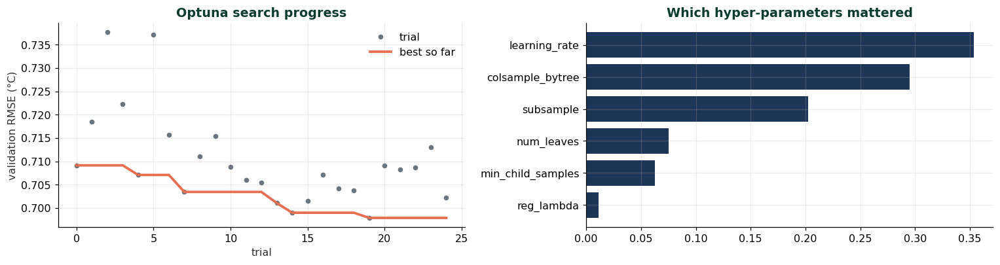

,best value
learning_rate,0.014937
num_leaves,65.000000
min_child_samples,19.000000
subsample,0.619747
colsample_bytree,0.609518
reg_lambda,0.012515


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [15]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
TUNED_PARAMS = None

if CFG["TUNE_TRIALS"] > 0:
    col = "Tair_t+60"
    y_tr, y_va = delta(idx_tr, col), delta(idx_va, col)
    def objective(trial):
        p = dict(n_estimators=3000, learning_rate=trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
                 num_leaves=trial.suggest_int("num_leaves", 15, 255, log=True),
                 min_child_samples=trial.suggest_int("min_child_samples", 10, 200, log=True),
                 subsample=trial.suggest_float("subsample", 0.5, 1.0), subsample_freq=1,
                 colsample_bytree=trial.suggest_float("colsample_bytree", 0.3, 1.0),
                 reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
                 random_state=SEED, n_jobs=-1, verbose=-1)
        m = lgb.LGBMRegressor(**p).fit(X_tr, y_tr, eval_set=[(X_va, y_va)], callbacks=[lgb.early_stopping(100, verbose=False)])
        return np.sqrt(mean_squared_error(y_va, m.predict(X_va)))
    study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
    t_tune = time.time(); study.optimize(objective, n_trials=CFG["TUNE_TRIALS"])
    TUNED_PARAMS = study.best_params

    fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
    vals = [t.value for t in study.trials]
    axes[0].plot(vals, "o", color=C["grey"], ms=4, label="trial"); axes[0].plot(np.minimum.accumulate(vals), color=C["orange"], lw=2.5, label="best so far")
    axes[0].set_xlabel("trial"); axes[0].set_ylabel("validation RMSE (°C)"); axes[0].set_title("Optuna search progress"); axes[0].legend()
    imp = optuna.importance.get_param_importances(study)
    axes[1].barh(list(imp)[::-1], list(imp.values())[::-1], color=C["blue"]); axes[1].set_title("Which hyper-parameters mattered")
    fig.tight_layout(); save(fig, "08_tuning"); plt.show()

    for col in TARGET_COLS:
        t = tgt_of(col); t0 = time.time()
        m = fit_tree("LightGBM-tuned", lgb.LGBMRegressor(n_estimators=3000, subsample_freq=1, random_state=SEED, n_jobs=-1,
                                                          verbose=-1, **TUNED_PARAMS), col)
        TRAIN_TIME[(col, "LightGBM-tuned")] = time.time() - t0
        FITTED[(col, "LightGBM-tuned")] = m
        PRED["val"][(col, "LightGBM-tuned")] = X_va[t] + m.predict(X_va)
        PRED["test"][(col, "LightGBM-tuned")] = X_te[t] + m.predict(X_te)
    section_banner(f"Tuning finished in {time.time()-t_tune:.0f}s · best validation RMSE {study.best_value:.3f} °C")
    display(pd.Series(TUNED_PARAMS).to_frame("best value"))
else:
    print("Tuning skipped (TUNE_TRIALS = 0)")

## 11 · Deep learning: LSTM and GRU
Input: the last hour (12 steps × all features), scaled with **training-set statistics only**. Output: the change at both horizons. Two stacked recurrent layers, dropout, early stopping and learning-rate decay.

✓ Tair   LSTM: 13 epochs · 30s
✓ Tair   GRU: 9 epochs · 18s
✓ Rhair  LSTM: 8 epochs · 16s
✓ Rhair  GRU: 11 epochs · 20s


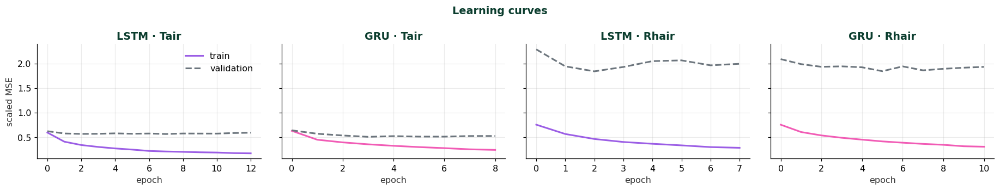

In [16]:
import tensorflow as tf
from tensorflow import keras
tf.random.set_seed(SEED)
gpu = tf.config.list_physical_devices("GPU")
section_banner(f"TensorFlow {tf.__version__} · {'GPU ✓' if gpu else 'CPU only (works, just slower)'}")

SCALER = StandardScaler().fit(X_tr.values)
X_scaled = SCALER.transform(X_all.values).astype("float32")
ALL_TIMES = X_all.index.values

def windows(index_subset):
    L = CFG["SEQ_LEN"]; pos = X_all.index.get_indexer(index_subset)
    okw = pos >= L - 1
    okw[okw] = (ALL_TIMES[pos[okw]] - ALL_TIMES[pos[okw] - (L - 1)]) == np.timedelta64(CFG["STEP_MIN"] * (L - 1), "m")
    p = pos[okw]
    return np.stack([X_scaled[i - L + 1:i + 1] for i in p]), X_all.index[p]

W = {k: windows(ix) for k, ix in [("tr", idx_tr), ("va", idx_va), ("te", idx_te)]}

def build(kind, n_out):
    Cell = keras.layers.LSTM if kind == "LSTM" else keras.layers.GRU
    m = keras.Sequential([keras.layers.Input(shape=(CFG["SEQ_LEN"], len(FEATURES))),
                          Cell(64, return_sequences=True), keras.layers.Dropout(0.2), Cell(32),
                          keras.layers.Dense(32, activation="relu"), keras.layers.Dense(n_out)])
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")
    return m

HIST = {}
for t in CFG["TARGETS"]:
    cols = [c for c in TARGET_COLS if tgt_of(c) == t]
    d = {k: Y_all.loc[W[k][1], cols].values - X_all.loc[W[k][1], [t]].values for k in W}
    sd = d["tr"].std(axis=0)
    for kind in ["LSTM", "GRU"]:
        t0 = time.time(); model = build(kind, len(cols))
        h = model.fit(W["tr"][0], d["tr"] / sd, validation_data=(W["va"][0], d["va"] / sd), epochs=CFG["EPOCHS"],
                      batch_size=CFG["BATCH"], verbose=0,
                      callbacks=[keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True),
                                 keras.callbacks.ReduceLROnPlateau(patience=3, factor=0.5)])
        HIST[(t, kind)] = h.history
        for split, k in [("val", "va"), ("test", "te")]:
            pdelta = model.predict(W[k][0], verbose=0) * sd
            for j, c in enumerate(cols):
                PRED[split][(c, kind)] = pd.Series(X_all.loc[W[k][1], t].values + pdelta[:, j], index=W[k][1])
        for c in cols:
            FITTED[(c, kind)] = model; TRAIN_TIME[(c, kind)] = time.time() - t0
        print(f"✓ {t:6s} {kind}: {len(h.history['loss'])} epochs · {time.time()-t0:.0f}s")

fig, axes = plt.subplots(1, len(HIST), figsize=(4.2 * len(HIST), 3.2), sharey=True)
for ax, ((t, kind), hst) in zip(np.atleast_1d(axes), HIST.items()):
    ax.plot(hst["loss"], color=PALETTE[kind], lw=2, label="train"); ax.plot(hst["val_loss"], color=C["grey"], lw=2, ls="--", label="validation")
    ax.set_title(f"{kind} · {t}"); ax.set_xlabel("epoch")
np.atleast_1d(axes)[0].set_ylabel("scaled MSE"); np.atleast_1d(axes)[0].legend()
fig.suptitle("Learning curves", weight="bold", color=C["dark"]); fig.tight_layout(); save(fig, "09_learning_curves"); plt.show()

## 12 · Ensemble chosen on validation data
For each target, the **three models with the lowest validation RMSE** are averaged. The members are chosen without looking at the test set, so the ensemble's test score is honest.

In [17]:
def rmse(a, b):
    m = a.notna() & b.notna()
    return np.sqrt(mean_squared_error(a[m], b[m]))

ENSEMBLE_MEMBERS = {}
for col in TARGET_COLS:
    y_va = Y_all.loc[idx_va, col]
    scores = {m: rmse(y_va, PRED["val"][(col, m)].reindex(idx_va)) for (c, m) in PRED["val"] if c == col and m != "Persistence"}
    top = sorted(scores, key=scores.get)[:3]
    ENSEMBLE_MEMBERS[col] = top
    for split, ix in [("val", idx_va), ("test", idx_te)]:
        PRED[split][(col, "Ensemble")] = pd.concat([PRED[split][(col, m)].reindex(ix) for m in top], axis=1).mean(axis=1, skipna=True)
pd.DataFrame({c: ", ".join(m) for c, m in ENSEMBLE_MEMBERS.items()}, index=["ensemble members (by validation RMSE)"]).T

,ensemble members (by validation RMSE)
Tair_t+30,"LightGBM, LightGBM-tuned, XGBoost"
Tair_t+60,"LightGBM-tuned, RandomForest, XGBoost"
Rhair_t+30,"LightGBM, LightGBM-tuned, RandomForest"
Rhair_t+60,"XGBoost, LightGBM-tuned, LightGBM"


## 13 · Uncertainty: calibrated 80 % prediction intervals
A point forecast alone does not say how much to trust it. Two extra LightGBM models predict the **10th and 90th percentiles** (quantile loss). Trained on winter data, these bands are usually **too narrow** for the more variable spring test weeks.

The fix is **conformalized quantile regression (CQR)** (Romano et al., 2019). On the validation weeks, measure how far real values fall outside the raw band, then widen every band by that amount. This gives coverage close to the stated 80 % without retraining. Both versions are reported, so you can show the improvement.

target,raw_coverage_pct,calibrated_coverage_pct,raw_width,calibrated_width,unit
Tair_t+30,63.120000,79.190000,0.950000,1.270000,°C
Tair_t+60,62.550000,78.210000,1.380000,1.850000,°C
Rhair_t+30,63.990000,72.990000,5.900000,6.750000,% RH
Rhair_t+60,54.890000,66.800000,8.180000,9.820000,% RH


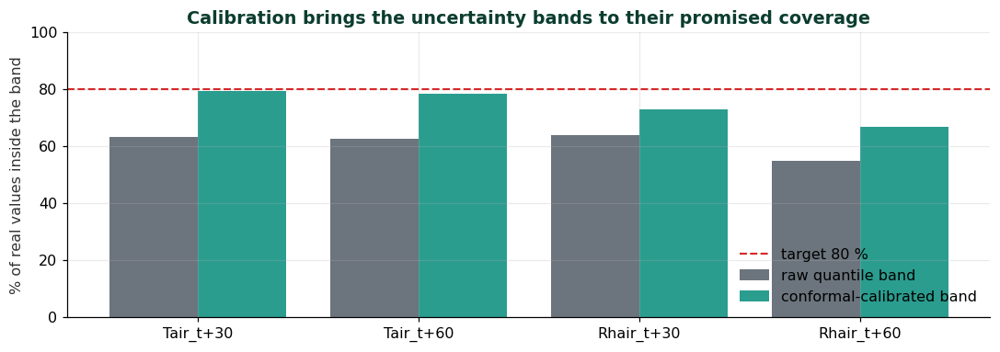

Target coverage: 80 %. The calibrated bands are used everywhere below (showcase, dashboard, IoT API).


In [18]:
INTERVALS, COVERAGE, CQR_Q = {}, [], {}
qlo, qhi = CFG["INTERVAL"]; alpha = 1 - (qhi - qlo)
for col in TARGET_COLS:
    t = tgt_of(col); b = {"val": {}, "test": {}}
    for q in (qlo, qhi):
        m = lgb.LGBMRegressor(objective="quantile", alpha=q, n_estimators=800, learning_rate=0.05, num_leaves=31,
                              random_state=SEED, n_jobs=-1, verbose=-1)
        m.fit(X_tr, delta(idx_tr, col))
        FITTED[(col, f"Q{int(q*100)}")] = m
        b["val"][q], b["test"][q] = X_va[t] + m.predict(X_va), X_te[t] + m.predict(X_te)
    lo_v, hi_v = np.minimum(b["val"][qlo], b["val"][qhi]), np.maximum(b["val"][qlo], b["val"][qhi])
    lo_t, hi_t = np.minimum(b["test"][qlo], b["test"][qhi]), np.maximum(b["test"][qlo], b["test"][qhi])
    y_v, y_t = Y_all.loc[idx_va, col], Y_all.loc[idx_te, col]
    score = np.maximum(lo_v - y_v, y_v - hi_v)                       # how far outside the band (negative = inside)
    nv = len(score); Q = float(np.quantile(score, min(1.0, (1 - alpha) * (nv + 1) / nv)))
    CQR_Q[col] = Q
    lo_c, hi_c = lo_t - Q, hi_t + Q
    INTERVALS[col] = (lo_c, hi_c)
    cov = lambda lo, hi: 100 * ((y_t >= lo) & (y_t <= hi)).mean()
    COVERAGE.append(dict(target=col, raw_coverage_pct=cov(lo_t, hi_t), calibrated_coverage_pct=cov(lo_c, hi_c),
                         raw_width=(hi_t - lo_t).mean(), calibrated_width=(hi_c - lo_c).mean(), unit=UNIT[t]))
COVERAGE = pd.DataFrame(COVERAGE)
display(COVERAGE.round(2).style.hide(axis="index")
        .bar(subset=["raw_coverage_pct", "calibrated_coverage_pct"], color="#95d5b2", vmin=0, vmax=100))
fig, ax = plt.subplots(figsize=(10, 3.6)); x = np.arange(len(COVERAGE))
ax.bar(x - 0.2, COVERAGE.raw_coverage_pct, 0.4, color=C["grey"], label="raw quantile band")
ax.bar(x + 0.2, COVERAGE.calibrated_coverage_pct, 0.4, color=C["teal"], label="conformal-calibrated band")
ax.axhline(100 * (qhi - qlo), color=C["red"], ls="--", lw=1.4, label="target 80 %")
ax.set_xticks(x); ax.set_xticklabels(COVERAGE.target); ax.set_ylabel("% of real values inside the band"); ax.set_ylim(0, 100)
ax.legend(loc="lower right"); ax.set_title("Calibration brings the uncertainty bands to their promised coverage")
fig.tight_layout(); save(fig, "09b_interval_calibration"); plt.show()
print(f"Target coverage: {100*(qhi-qlo):.0f} %. The calibrated bands are used everywhere below (showcase, dashboard, IoT API).")

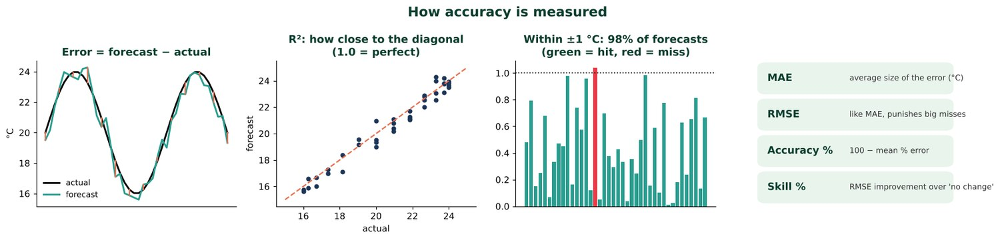

## 14 · Leaderboard (test set)
All models are scored on **exactly the same test rows**. **Skill** = how much lower the RMSE is than the *persistence* baseline: positive means the model adds real value, negative means it does worse than assuming nothing changes.

#### Tair_t+30  ·  tolerance ±1 °C

,accuracy,R2,MSE,RMSE,MAE,within_tol,skill_pct,train_s
model,,,,,,,,
RandomForest,98.25%,0.9746,0.345,0.587,0.415,91.1%,+20.5%,104.0
Ensemble,98.23%,0.9740,0.353,0.594,0.423,90.8%,+19.5%,0.0
LightGBM-tuned,98.23%,0.9740,0.354,0.595,0.422,90.8%,+19.5%,10.0
LightGBM,98.21%,0.9739,0.354,0.595,0.425,90.6%,+19.4%,8.2
XGBoost,98.18%,0.9729,0.368,0.607,0.434,90.1%,+17.9%,12.0
GRU,97.96%,0.9688,0.424,0.651,0.477,88.6%,+11.8%,17.7
LSTM,97.66%,0.9608,0.532,0.730,0.541,83.4%,+1.2%,30.0
Persistence,97.60%,0.9599,0.545,0.738,0.562,85.4%,+0.0%,0.0
Ridge,97.66%,0.9470,0.721,0.849,0.560,84.9%,-15.0%,0.1


#### Tair_t+60  ·  tolerance ±1 °C

,accuracy,R2,MSE,RMSE,MAE,within_tol,skill_pct,train_s
model,,,,,,,,
RandomForest,97.41%,0.9544,0.620,0.787,0.600,83.5%,+35.0%,100.2
Ensemble,97.29%,0.9496,0.685,0.827,0.633,81.1%,+31.7%,0.0
LightGBM-tuned,97.22%,0.9475,0.714,0.845,0.647,80.5%,+30.2%,13.2
LightGBM,97.14%,0.9438,0.764,0.874,0.668,78.9%,+27.8%,14.4
XGBoost,97.08%,0.9400,0.815,0.903,0.686,76.1%,+25.4%,13.3
GRU,96.69%,0.9255,1.013,1.006,0.765,71.3%,+16.9%,17.7
LSTM,96.47%,0.9142,1.166,1.080,0.817,68.1%,+10.8%,30.0
Persistence,95.86%,0.8921,1.466,1.211,0.960,57.6%,+0.0%,0.0
Ridge,96.07%,0.8759,1.686,1.299,0.930,63.8%,-7.2%,0.1


#### Rhair_t+30  ·  tolerance ±5 % RH

,accuracy,R2,MSE,RMSE,MAE,within_tol,skill_pct,train_s
model,,,,,,,,
LightGBM,95.99%,0.8686,17.199,4.147,2.697,83.9%,+0.3%,3.5
Persistence,95.94%,0.8679,17.301,4.160,2.838,82.1%,+0.0%,0.0
Ensemble,95.95%,0.8673,17.375,4.168,2.727,83.8%,-0.2%,0.0
LightGBM-tuned,95.95%,0.8667,17.450,4.177,2.716,83.6%,-0.4%,5.2
RandomForest,95.84%,0.8635,17.870,4.227,2.809,83.1%,-1.6%,115.0
XGBoost,95.85%,0.8631,17.923,4.234,2.832,83.9%,-1.8%,5.4
Ridge,95.59%,0.8534,19.193,4.381,2.985,82.3%,-5.3%,0.1
LSTM,95.38%,0.8393,21.047,4.588,3.096,79.6%,-10.3%,16.2
GRU,95.21%,0.8358,21.494,4.636,3.279,78.2%,-11.5%,20.0


#### Rhair_t+60  ·  tolerance ±5 % RH

,accuracy,R2,MSE,RMSE,MAE,within_tol,skill_pct,train_s
model,,,,,,,,
LightGBM-tuned,93.82%,0.7302,35.337,5.945,4.169,70.7%,+2.3%,6.6
Ensemble,93.74%,0.7259,35.896,5.991,4.211,70.3%,+1.5%,0.0
XGBoost,93.63%,0.7226,36.327,6.027,4.290,69.4%,+0.9%,7.8
LightGBM,93.72%,0.7183,36.900,6.075,4.221,70.5%,+0.2%,3.6
Persistence,93.87%,0.7174,37.013,6.084,4.299,68.0%,+0.0%,0.0
RandomForest,92.90%,0.6436,46.684,6.833,4.747,67.6%,-12.3%,101.6
Ridge,92.64%,0.6312,48.308,6.950,4.893,65.7%,-14.2%,0.1
LSTM,92.76%,0.6278,48.747,6.982,4.772,64.5%,-14.8%,16.2
GRU,92.62%,0.6267,48.896,6.993,4.972,61.3%,-14.9%,20.0


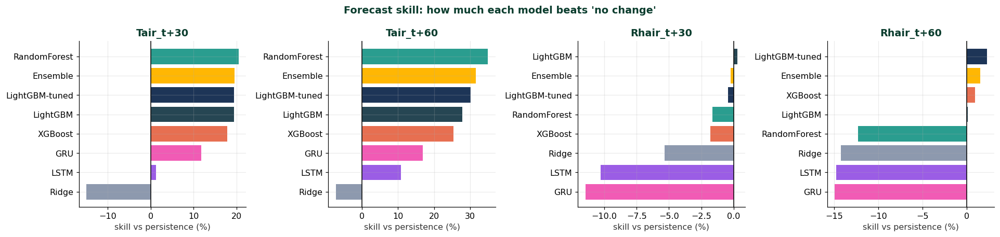

In [19]:
MODELS = ["Persistence", "Ridge", "RandomForest", "XGBoost", "LightGBM", "LightGBM-tuned", "LSTM", "GRU", "Ensemble"]
rows = []
for col in TARGET_COLS:
    t = tgt_of(col)
    avail = [m for m in MODELS if (col, m) in PRED["test"]]
    frame = pd.concat({m: PRED["test"][(col, m)].reindex(idx_te) for m in avail}, axis=1)
    frame["y"] = Y_all.loc[idx_te, col]
    frame = frame.dropna()                                  # common rows for a fair comparison
    pers = np.sqrt(mean_squared_error(frame.y, frame["Persistence"]))
    for m in avail:
        e = frame[m] - frame.y
        r = np.sqrt((e ** 2).mean())
        rows.append(dict(target=col, model=m, accuracy=100 - 100 * (e.abs() / frame.y.abs()).mean(),
                         R2=r2_score(frame.y, frame[m]), MSE=r ** 2, RMSE=r, MAE=e.abs().mean(),
                         within_tol=100 * (e.abs() <= TOL[t]).mean(), skill_pct=100 * (1 - r / pers),
                         train_s=TRAIN_TIME.get((col, m), 0.0), n_test=len(frame)))
LB = pd.DataFrame(rows)
LB.to_csv(os.path.join(CFG["OUT_DIR"], "leaderboard.csv"), index=False)
BEST = LB[LB.model != "Persistence"].loc[lambda d: d.groupby("target").RMSE.idxmin()].set_index("target")

for col in TARGET_COLS:
    t = tgt_of(col)
    tab = LB[LB.target == col].drop(columns=["target", "n_test"]).sort_values("RMSE").set_index("model")
    display(Markdown(f"#### {col}  ·  tolerance ±{TOL[t]:g} {UNIT[t]}"))
    display(tab.style.format({"accuracy": "{:.2f}%", "R2": "{:.4f}", "MSE": "{:.3f}", "RMSE": "{:.3f}", "MAE": "{:.3f}", "within_tol": "{:.1f}%", "skill_pct": "{:+.1f}%", "train_s": "{:.1f}"})
            .background_gradient(subset=["MSE", "RMSE", "MAE"], cmap="RdYlGn_r").background_gradient(subset=["accuracy", "R2", "within_tol"], cmap="RdYlGn")
            .bar(subset=["skill_pct"], align="zero", color=["#f4a3a3", "#95d5b2"]))

fig, axes = plt.subplots(1, len(TARGET_COLS), figsize=(4.4 * len(TARGET_COLS), 4.2), sharey=False)
for ax, col in zip(axes, TARGET_COLS):
    d = LB[(LB.target == col) & (LB.model != "Persistence")].sort_values("skill_pct")
    ax.barh(d.model, d.skill_pct, color=[PALETTE.get(m, C["grey"]) for m in d.model])
    ax.axvline(0, color="black", lw=1); ax.set_title(col); ax.set_xlabel("skill vs persistence (%)")
fig.suptitle("Forecast skill: how much each model beats 'no change'", weight="bold", color=C["dark"])
fig.tight_layout(); save(fig, "10_skill_scores"); plt.show()

### Accuracy scoreboard
Headline numbers for the best model on each target (test set, never seen during training or tuning).

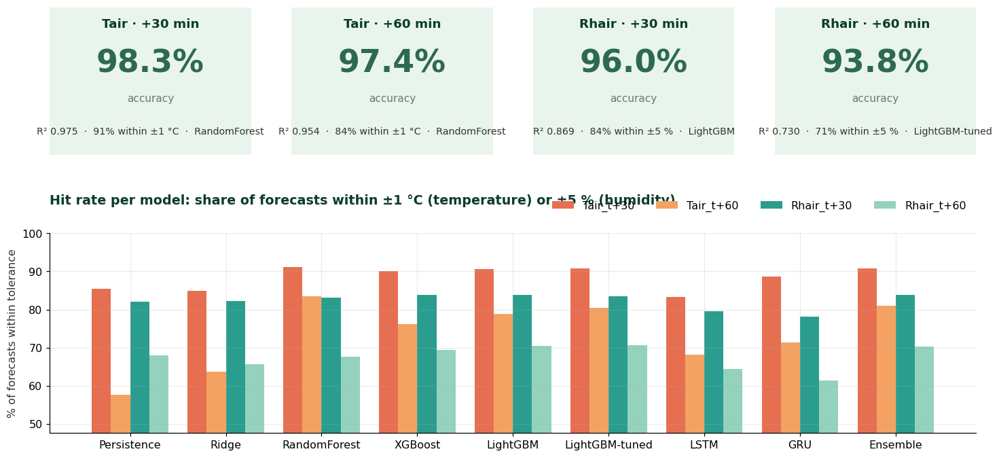

In [20]:
fig = plt.figure(figsize=(16, 7.4))
gs = fig.add_gridspec(2, len(TARGET_COLS), height_ratios=[1, 1.35], hspace=0.45)
for k, col in enumerate(TARGET_COLS):
    t, r = tgt_of(col), BEST.loc[col]
    a = fig.add_subplot(gs[0, k]); a.axis("off")
    a.add_patch(plt.Rectangle((0, 0), 1, 1, transform=a.transAxes, color="#e9f5ec", zorder=0))
    a.text(0.5, 0.86, col.replace("_t+", " · +") + " min", ha="center", fontsize=12, weight="bold", color=C["dark"], transform=a.transAxes)
    a.text(0.5, 0.56, f"{r.accuracy:.1f}%", ha="center", fontsize=30, weight="bold", color=C["green"], transform=a.transAxes)
    a.text(0.5, 0.36, "accuracy", ha="center", fontsize=10, color=C["grey"], transform=a.transAxes)
    a.text(0.5, 0.14, f"R² {r.R2:.3f}  ·  {r.within_tol:.0f}% within ±{TOL[t]:g} {UNIT[t].split()[0]}  ·  {r.model}",
           ha="center", fontsize=9.3, color="#333", transform=a.transAxes)
ax = fig.add_subplot(gs[1, :])
models_order = [m for m in MODELS if m in LB.model.unique()]
w = 0.8 / len(TARGET_COLS); x = np.arange(len(models_order))
tc = [C["orange"], "#f4a261", C["teal"], "#94d2bd"]
for k, col in enumerate(TARGET_COLS):
    v = LB[LB.target == col].set_index("model").reindex(models_order)["within_tol"]
    ax.bar(x + (k - (len(TARGET_COLS) - 1) / 2) * w, v, w, color=tc[k % 4], label=col)
ax.set_xticks(x); ax.set_xticklabels(models_order); ax.set_ylabel("% of forecasts within tolerance")
ax.set_ylim(max(0, LB.within_tol.min() - 10), 100); ax.legend(ncol=4, loc="lower right", bbox_to_anchor=(1.0, 1.06))
ax.set_title("Hit rate per model: share of forecasts within ±1 °C (temperature) or ±5 % (humidity)", loc="left", pad=28)
save(fig, "10b_accuracy_scoreboard"); plt.show()

## 15 · Error analysis for the best model per target

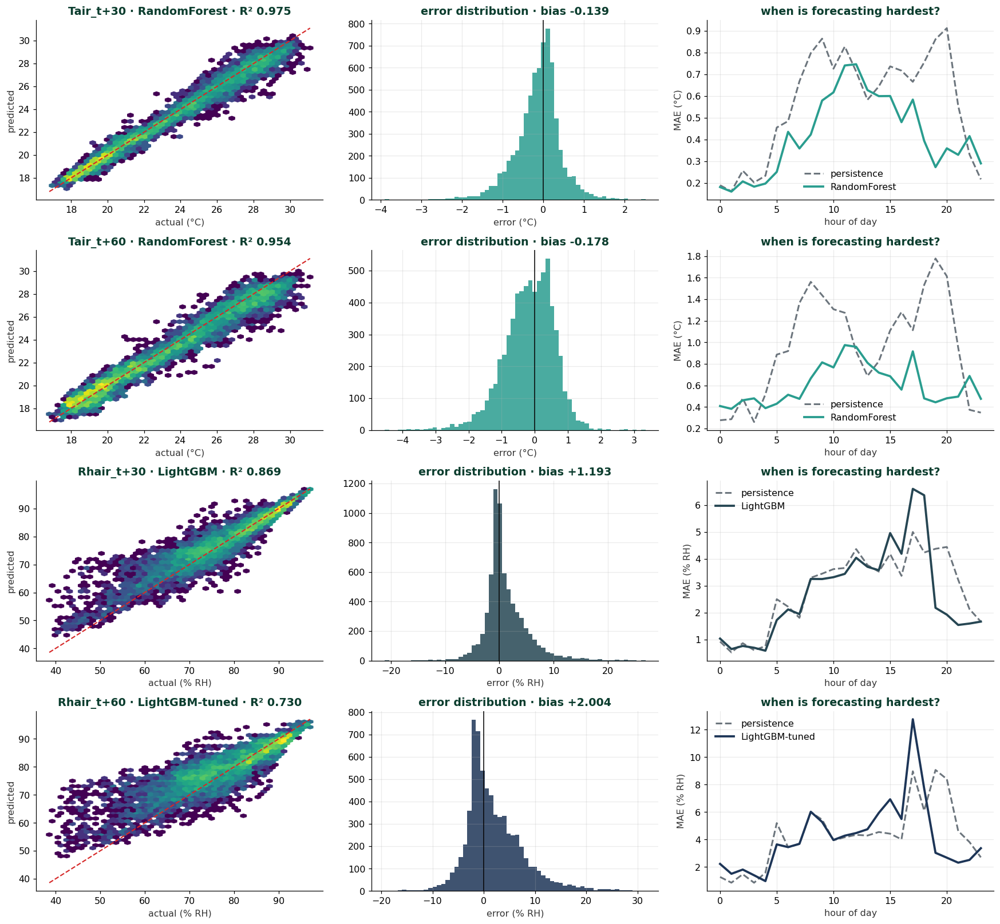

In [21]:
fig, axes = plt.subplots(len(TARGET_COLS), 3, figsize=(16, 3.7 * len(TARGET_COLS)))
for r, col in enumerate(TARGET_COLS):
    t, mname = tgt_of(col), BEST.loc[col, "model"]
    p = PRED["test"][(col, mname)].reindex(idx_te); y = Y_all.loc[idx_te, col]
    mk = p.notna(); p, y = p[mk], y[mk]; e = p - y
    ax = axes[r, 0]
    hb = ax.hexbin(y, p, gridsize=45, cmap="viridis", mincnt=1, bins="log")
    lim = [min(y.min(), p.min()), max(y.max(), p.max())]; ax.plot(lim, lim, color=C["red"], lw=1.4, ls="--")
    ax.set_xlabel(f"actual ({UNIT[t]})"); ax.set_ylabel("predicted"); ax.set_title(f"{col} · {mname} · R² {BEST.loc[col,'R2']:.3f}"); ax.grid(False)
    ax = axes[r, 1]
    ax.hist(e, bins=60, color=PALETTE.get(mname, C["teal"]), alpha=0.85); ax.axvline(0, color="black", lw=1)
    ax.set_xlabel(f"error ({UNIT[t]})"); ax.set_title(f"error distribution · bias {e.mean():+.3f}")
    ax = axes[r, 2]
    pers_e = (PRED["test"][(col, "Persistence")].reindex(y.index) - y).abs()
    by_h = pd.DataFrame({"model": e.abs(), "persistence": pers_e}).groupby(y.index.hour).mean()
    ax.plot(by_h.index, by_h["persistence"], color=C["grey"], lw=2, ls="--", label="persistence")
    ax.plot(by_h.index, by_h["model"], color=PALETTE.get(mname, C["teal"]), lw=2.5, label=mname)
    ax.set_xlabel("hour of day"); ax.set_ylabel(f"MAE ({UNIT[t]})"); ax.set_title("when is forecasting hardest?"); ax.legend()
fig.tight_layout(); save(fig, "11_error_analysis"); plt.show()

## 16 · Forecast showcase
Three test days: the real value, the best model's 60-minute-ahead forecast with its 80 % band, and the persistence baseline.

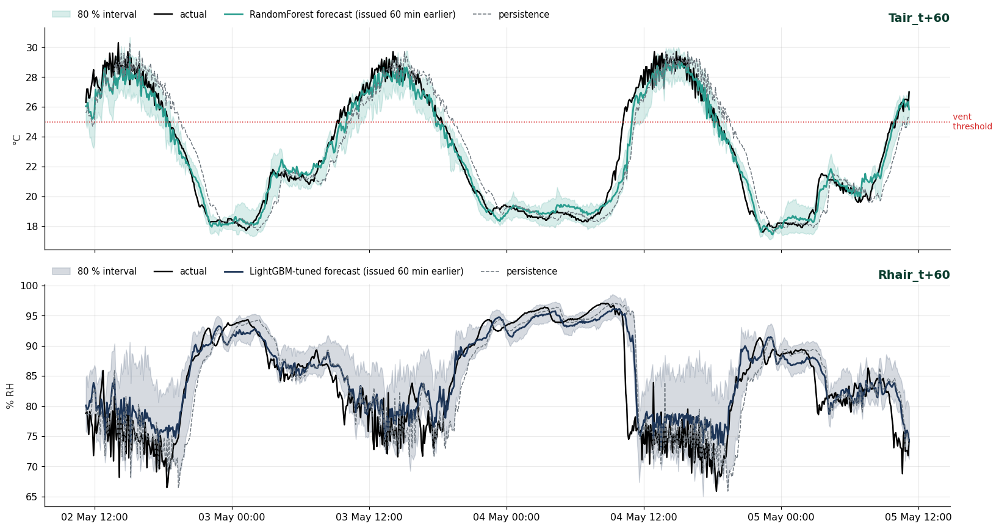

In [22]:
span = slice(0, 3 * 24 * 60 // CFG["STEP_MIN"])
fig, axes = plt.subplots(len(CFG["TARGETS"]), 1, figsize=(15, 4 * len(CFG["TARGETS"])), sharex=True)
for ax, t in zip(np.atleast_1d(axes), CFG["TARGETS"]):
    col = f"{t}_t+60"; mname = BEST.loc[col, "model"]
    tt = (idx_te + pd.Timedelta(minutes=60))[span]
    lo, hi = INTERVALS[col]
    ax.fill_between(tt, lo.values[span], hi.values[span], color=PALETTE.get(mname, C["teal"]), alpha=0.18, label="80 % interval")
    ax.plot(tt, Y_all.loc[idx_te, col].values[span], color="black", lw=1.6, label="actual")
    ax.plot(tt, PRED["test"][(col, mname)].reindex(idx_te).values[span], color=PALETTE.get(mname, C["teal"]), lw=1.8, label=f"{mname} forecast (issued 60 min earlier)")
    ax.plot(tt, PRED["test"][(col, "Persistence")].values[span], color=C["grey"], lw=1, ls="--", label="persistence")
    if t == "Tair":
        ax.axhline(CFG["VENT_T"], color=C["red"], lw=1, ls=":")
        ax.text(1.0, CFG["VENT_T"], " vent\n threshold", color=C["red"], fontsize=9, va="center", transform=ax.get_yaxis_transform())
    ax.set_ylabel(UNIT[t]); ax.set_title(col, loc="right")
    ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=4, fontsize=9.5)
np.atleast_1d(axes)[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b %H:%M"))
fig.tight_layout(); save(fig, "12_forecast_showcase"); plt.show()

### Interactive explorer
Zoom, pan and hover. Drag the range slider below the chart to move through the whole test period.

In [23]:
import plotly.graph_objects as go
col = "Tair_t+60"; mname = BEST.loc[col, "model"]; tt = idx_te + pd.Timedelta(minutes=60); lo, hi = INTERVALS[col]
fig = go.Figure()
fig.add_trace(go.Scatter(x=tt, y=hi, line=dict(width=0), showlegend=False, hoverinfo="skip"))
fig.add_trace(go.Scatter(x=tt, y=lo, fill="tonexty", fillcolor="rgba(29,53,87,0.15)", line=dict(width=0), name="80 % interval"))
fig.add_trace(go.Scatter(x=tt, y=Y_all.loc[idx_te, col], name="actual", line=dict(color="black", width=1.5)))
fig.add_trace(go.Scatter(x=tt, y=PRED["test"][(col, mname)].reindex(idx_te), name=f"{mname} forecast", line=dict(color=PALETTE.get(mname), width=1.8)))
fig.add_trace(go.Scatter(x=tt, y=PRED["test"][(col, "Persistence")], name="persistence", line=dict(color="#adb5bd", dash="dash")))
fig.add_hline(y=CFG["VENT_T"], line_dash="dot", line_color="#d62828", annotation_text="vent threshold")
fig.update_layout(title=f"Greenhouse air temperature — 60-minute forecast ({mname})", yaxis_title="°C", template="plotly_white",
                  height=480, hovermode="x unified", xaxis=dict(rangeslider=dict(visible=True), range=[tt[0], tt[0] + pd.Timedelta(days=3)]))
fig.show()

## 17 · Explainable AI with SHAP
**Global:** which inputs drive the 60-minute temperature forecast overall. **Local:** why the model made one particular forecast. A grower or examiner can check that the reasons make physical sense.

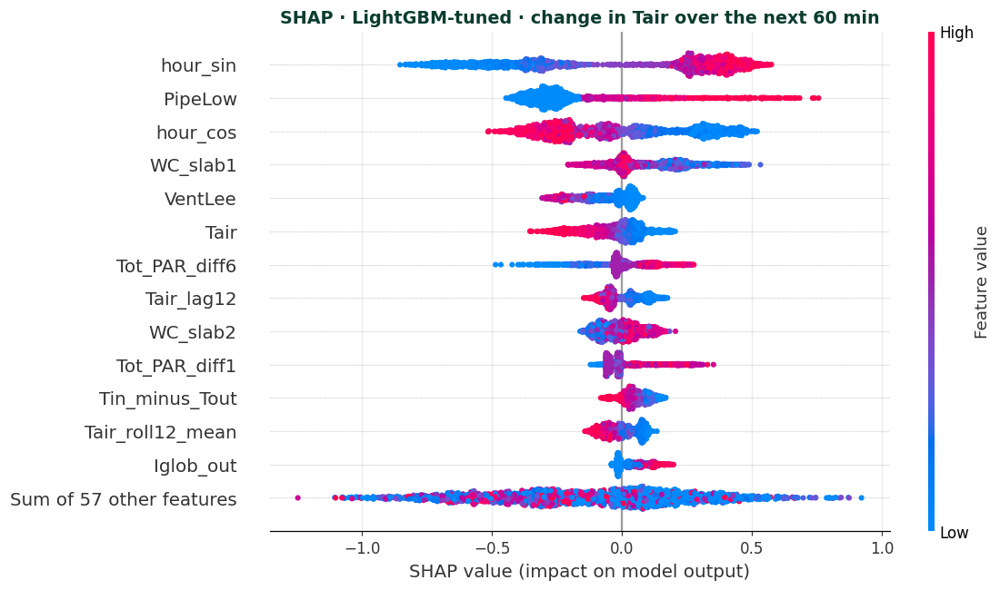

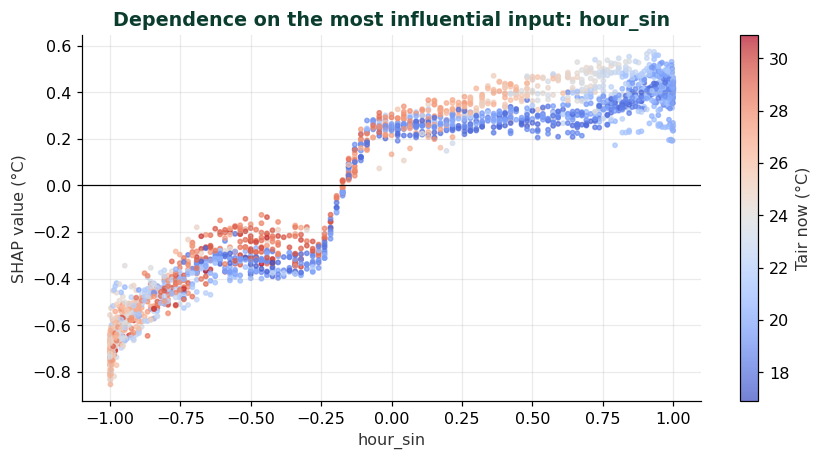

In [24]:
import shap
col = "Tair_t+60"
tree_name = next(m for m in ["LightGBM-tuned", "LightGBM", "XGBoost"] if (col, m) in FITTED)
explainer = shap.TreeExplainer(FITTED[(col, tree_name)])
sample = X_te.sample(min(2000, len(X_te)), random_state=SEED)
sv = explainer(sample)

plt.figure(); shap.plots.beeswarm(sv, max_display=14, show=False)
plt.title(f"SHAP · {tree_name} · change in Tair over the next 60 min", color=C["dark"], weight="bold")
plt.gcf().set_size_inches(10, 6.5); save(plt.gcf(), "13_shap_beeswarm"); plt.show()

imp = pd.Series(np.abs(sv.values).mean(0), index=sample.columns).sort_values(ascending=False)
top = imp.index[0]
fig, ax = plt.subplots(figsize=(8, 4.3))
sc = ax.scatter(sample[top], sv[:, top].values, c=sample["Tair"], cmap="coolwarm", s=8, alpha=0.7)
ax.axhline(0, color="black", lw=0.8); fig.colorbar(sc, ax=ax, label="Tair now (°C)")
ax.set_xlabel(top); ax.set_ylabel("SHAP value (°C)"); ax.set_title(f"Dependence on the most influential input: {top}")
fig.tight_layout(); save(fig, "14_shap_dependence"); plt.show()

### Explaining one forecast
The test moment with the largest predicted warming: which inputs pushed the forecast up or down?

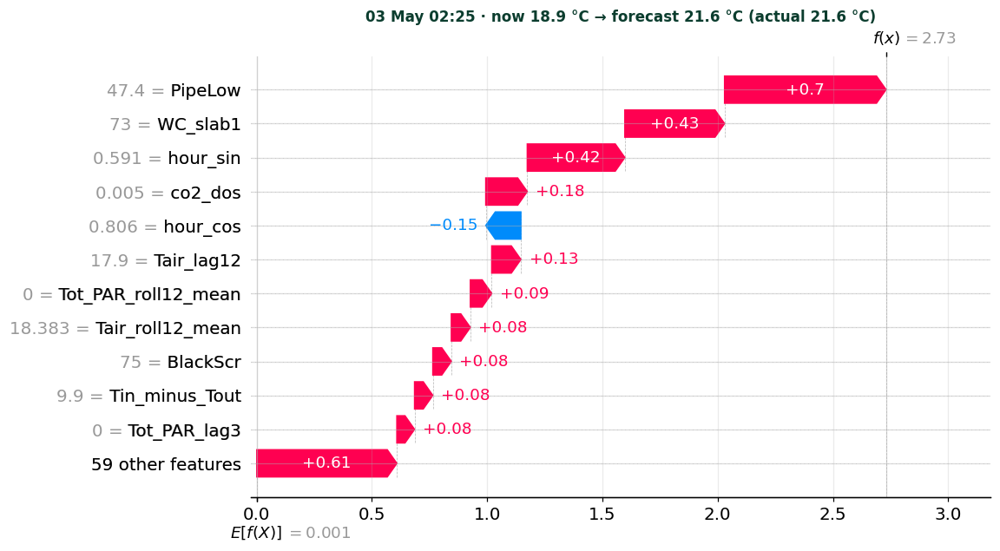

In [25]:
delta_pred = PRED["test"][(col, tree_name)] - X_te["Tair"]
moment = delta_pred.idxmax()
sv1 = explainer(X_te.loc[[moment]])
plt.figure(); shap.plots.waterfall(sv1[0], max_display=12, show=False)
plt.title(f"{moment:%d %b %H:%M} · now {X_te.loc[moment,'Tair']:.1f} °C → forecast {PRED['test'][(col, tree_name)][moment]:.1f} °C "
          f"(actual {Y_all.loc[moment, col]:.1f} °C)", color=C["dark"], weight="bold", fontsize=11)
plt.gcf().set_size_inches(10, 6); save(plt.gcf(), "15_shap_waterfall"); plt.show()

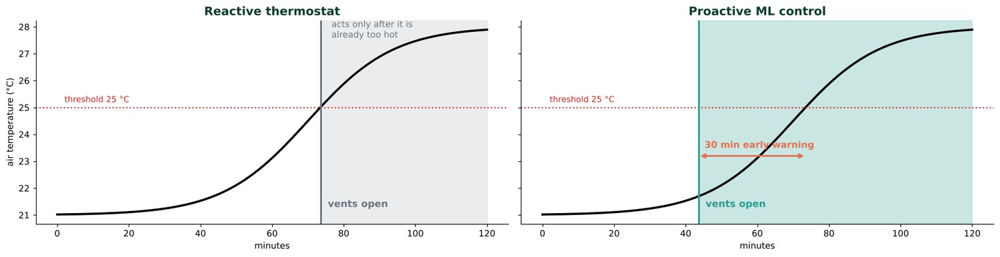

## 18 · From forecast to action: proactive vs reactive control
| Rule | Action |
|---|---|
| Tair at t+30 > `VENT_T` **or** RH at t+30 > `RH_HIGH` | **VENTILATE** |
| Tair at t+30 < `HEAT_T` | **HEAT** |
| Substrate water content < 20th percentile of training data **and** sunlight rising | **IRRIGATE** |

The **reactive** controller is a classic thermostat that only looks at *current* readings. The **proactive** controller uses the 30-minute forecast. Each is scored against what the future actually required. **Lead time** measures how many minutes before the greenhouse crosses `VENT_T` the proactive controller raises the alarm. Only real warm-ups count: the temperature must have been below the threshold for at least an hour first.

action,controller,events,accuracy,precision,recall,F1
VENTILATE,Proactive (ML),3139,93.7%,0.958000,0.903000,0.929000
VENTILATE,Reactive (thermostat),3139,91.5%,0.907000,0.909000,0.908000
HEAT,Proactive (ML),264,97.2%,0.646000,0.621000,0.633000
HEAT,Reactive (thermostat),264,97.0%,0.610000,0.610000,0.610000


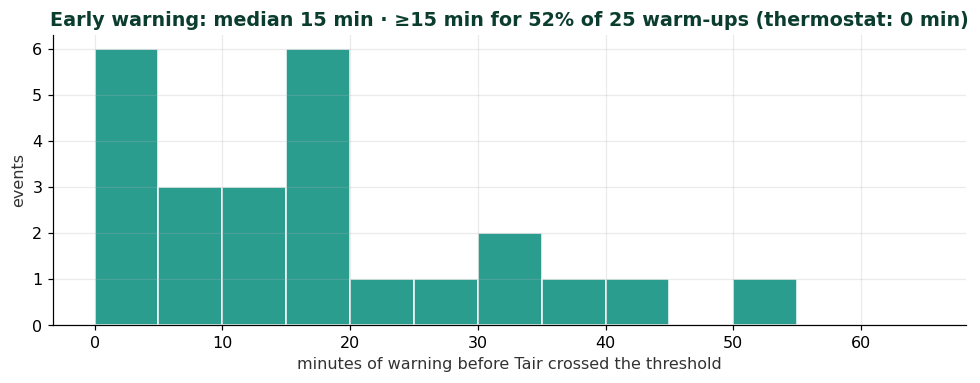

IRRIGATE rule: substrate water < 76.9 % with rising sunlight → recommended in 31.4% of test intervals (a demonstration rule: set the threshold from your crop's substrate recommendations)


In [26]:
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score
cT, cR = "Tair_t+30", "Rhair_t+30"
mT, mR = BEST.loc[cT, "model"], BEST.loc[cR, "model"]
D = pd.DataFrame({"T_now": X_te["Tair"], "RH_now": X_te["Rhair"],
                  "T_fut": Y_all.loc[idx_te, cT], "RH_fut": Y_all.loc[idx_te, cR],
                  "T_fc": PRED["test"][(cT, mT)].reindex(idx_te), "RH_fc": PRED["test"][(cR, mR)].reindex(idx_te)}).dropna()
rules = lambda T, RH: pd.DataFrame({"VENTILATE": (T > CFG["VENT_T"]) | (RH > CFG["RH_HIGH"]), "HEAT": T < CFG["HEAT_T"]})
truth, proactive, reactive = rules(D.T_fut, D.RH_fut), rules(D.T_fc, D.RH_fc), rules(D.T_now, D.RH_now)

rows = []
for a in truth:
    for name, dec in [("Proactive (ML)", proactive), ("Reactive (thermostat)", reactive)]:
        rows.append(dict(action=a, controller=name, events=int(truth[a].sum()), accuracy=accuracy_score(truth[a], dec[a]),
                         precision=precision_score(truth[a], dec[a], zero_division=0),
                         recall=recall_score(truth[a], dec[a], zero_division=0), F1=f1_score(truth[a], dec[a], zero_division=0)))
CONTROL = pd.DataFrame(rows)
display(CONTROL.round(3).style.hide(axis="index").format({"accuracy": "{:.1%}"})
        .background_gradient(subset=["accuracy", "F1"], cmap="Greens", vmin=0, vmax=1))

# Early-warning lead time: overheating onsets = Tair crosses VENT_T upward
temp = data["Tair"].reindex(idx_te)
# a real warm-up = Tair crosses VENT_T after at least 60 min below it (ignores flicker around the threshold)
below_1h = (temp <= CFG["VENT_T"]).astype(int).rolling(12).min().shift(1) == 1
onsets = temp.index[(temp > CFG["VENT_T"]) & below_1h]
alarm = (D.T_fc > CFG["VENT_T"])
leads = []
for tau in onsets:
    window = alarm.loc[tau - pd.Timedelta(minutes=60): tau]
    first = window[window].index.min() if window.any() else None
    leads.append(0 if first is None else (tau - first).total_seconds() / 60)
LEADS = pd.Series(leads, dtype=float)
if len(LEADS):
    fig, ax = plt.subplots(figsize=(9, 3.6))
    ax.hist(LEADS, bins=np.arange(0, 66, 5), color=C["teal"], edgecolor="white")
    ax.set_xlabel("minutes of warning before Tair crossed the threshold"); ax.set_ylabel("events")
    ax.set_title(f"Early warning: median {LEADS.median():.0f} min · ≥15 min for {100*(LEADS>=15).mean():.0f}% of {len(LEADS)} warm-ups (thermostat: 0 min)")
    fig.tight_layout(); save(fig, "16_lead_time"); plt.show()

if "WC_slab1" in X_te:
    wc_low = X_tr["WC_slab1"].quantile(0.20)
    irrigate = (X_te["WC_slab1"] < wc_low) & (X_te.get("Iglob_out_diff6", 0) > 0)
    print(f"IRRIGATE rule: substrate water < {wc_low:.1f} % with rising sunlight → recommended in {100*irrigate.mean():.1f}% of test intervals "
          "(a demonstration rule: set the threshold from your crop's substrate recommendations)")

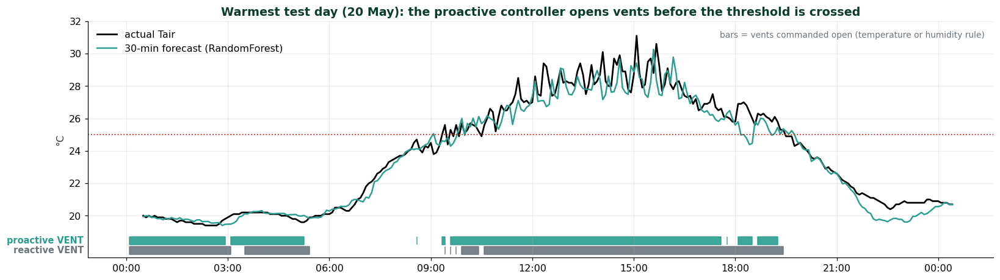

In [27]:
day = D.index[D.T_fut.groupby(D.index.date).transform("max") == D.T_fut.groupby(D.index.date).transform("max").max()][0].date()
dd = D.loc[str(day)]
fig, ax = plt.subplots(figsize=(15, 4.3))
ax.plot(dd.index + pd.Timedelta(minutes=30), dd.T_fut, color="black", lw=1.8, label="actual Tair")
ax.plot(dd.index + pd.Timedelta(minutes=30), dd.T_fc, color=PALETTE.get(mT, C["teal"]), lw=1.6, label=f"30-min forecast ({mT})")
ax.axhline(CFG["VENT_T"], color=C["red"], ls=":", lw=1.2)
y0 = ax.get_ylim()[0]
for k, (name, dec, colr) in enumerate([("proactive", proactive, C["teal"]), ("reactive", reactive, C["grey"])]):
    on = dec.loc[str(day), "VENTILATE"]
    ax.fill_between(on.index, y0 - 0.6 - 0.6 * k, y0 - 0.1 - 0.6 * k, where=on.values, color=colr, step="post", alpha=0.9)
    ax.text(-0.005, y0 - 0.35 - 0.6 * k, f"{name} VENT", va="center", ha="right", fontsize=9.5, color=colr, weight="bold",
            transform=ax.get_yaxis_transform())
ax.set_ylim(y0 - 1.4, ax.get_ylim()[1]); ax.legend(loc="upper left")
ax.set_yticks([v for v in ax.get_yticks() if v >= y0 + 0.3]); ax.set_ylabel("°C")
ax.text(0.99, 0.96, "bars = vents commanded open (temperature or humidity rule)", transform=ax.transAxes, ha="right", va="top", fontsize=9, color=C["grey"])
ax.set_title(f"Warmest test day ({day:%d %b}): the proactive controller opens vents before the threshold is crossed")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M")); fig.tight_layout(); save(fig, "17_control_timeline"); plt.show()

### Classification view of the ventilation decision
The VENTILATE command is a yes/no decision, so it is also judged with classification metrics: a **confusion matrix** for the proactive and reactive controllers, and a **ROC curve**. For the ROC curve, the forecast temperature margin above the threshold is used as a score, giving a threshold-free measure of how well forecasts separate "vent needed" from "not needed".

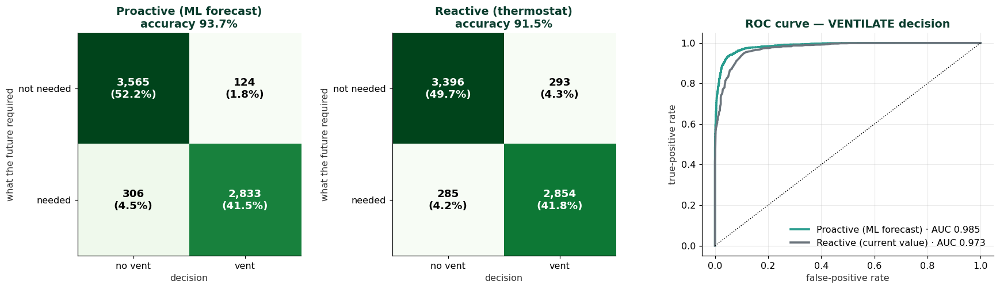

In [28]:
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw={"width_ratios": [1, 1, 1.25]})
for ax, (name, dec) in zip(axes[:2], [("Proactive (ML forecast)", proactive), ("Reactive (thermostat)", reactive)]):
    cmx = confusion_matrix(truth["VENTILATE"], dec["VENTILATE"], labels=[False, True])
    ax.imshow(cmx, cmap="Greens"); ax.grid(False)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cmx[i, j]:,}\n({100*cmx[i, j]/cmx.sum():.1f}%)", ha="center", va="center", fontsize=12,
                    color="white" if cmx[i, j] > cmx.max() / 2 else "black", weight="bold")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["no vent", "vent"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["not needed", "needed"])
    ax.set_xlabel("decision"); ax.set_ylabel("what the future required")
    ax.set_title(f"{name}\naccuracy {100*(cmx[0,0]+cmx[1,1])/cmx.sum():.1f}%")
score_fc = np.maximum(D.T_fc - CFG["VENT_T"], (D.RH_fc - CFG["RH_HIGH"]) / 5)    # °C-equivalent margin (5 % RH ≈ 1 °C)
score_now = np.maximum(D.T_now - CFG["VENT_T"], (D.RH_now - CFG["RH_HIGH"]) / 5)
ROC_AUC = {}
for name, sc, colr in [("Proactive (ML forecast)", score_fc, C["teal"]), ("Reactive (current value)", score_now, C["grey"])]:
    fpr, tpr, _ = roc_curve(truth["VENTILATE"], sc); ROC_AUC[name] = roc_auc_score(truth["VENTILATE"], sc)
    axes[2].plot(fpr, tpr, color=colr, lw=2.4, label=f"{name} · AUC {ROC_AUC[name]:.3f}")
axes[2].plot([0, 1], [0, 1], color="black", ls=":", lw=1); axes[2].set_xlabel("false-positive rate"); axes[2].set_ylabel("true-positive rate")
axes[2].set_title("ROC curve — VENTILATE decision"); axes[2].legend(loc="lower right")
fig.tight_layout(); save(fig, "17b_confusion_roc"); plt.show()

## 19 · Live greenhouse dashboard
Move the slider through the test period. The dashboard shows what an operator would see at each moment: current state, forecasts with uncertainty, and the recommended actions.

In [29]:
def dashboard(i=0):
    ts = idx_te[i]; hist = data.loc[ts - pd.Timedelta(hours=6): ts]
    fc = {h: PRED["test"][(f"Tair_t+{h}", BEST.loc[f"Tair_t+{h}", "model"])].get(ts, np.nan) for h in CFG["HORIZONS_MIN"]}
    rh = {h: PRED["test"][(f"Rhair_t+{h}", BEST.loc[f"Rhair_t+{h}", "model"])].get(ts, np.nan) for h in CFG["HORIZONS_MIN"]}
    lo, hi = INTERVALS["Tair_t+60"][0].get(ts, np.nan), INTERVALS["Tair_t+60"][1].get(ts, np.nan)
    acts = []
    if fc[30] > CFG["VENT_T"] or rh[30] > CFG["RH_HIGH"]: acts.append(("VENTILATE", C["teal"]))
    if fc[30] < CFG["HEAT_T"]: acts.append(("HEAT", C["orange"]))
    if "WC_slab1" in X_te and X_te.loc[ts, "WC_slab1"] < X_tr["WC_slab1"].quantile(0.2): acts.append(("IRRIGATE", C["blue"]))
    if not acts: acts.append(("ALL OK — HOLD", C["green"]))

    fig = plt.figure(figsize=(15, 5)); gs = fig.add_gridspec(2, 4, width_ratios=[2.6, 1, 1, 1])
    ax = fig.add_subplot(gs[:, 0])
    ax.plot(hist.index, hist["Tair"], color="black", lw=2, label="measured")
    fx = [ts + pd.Timedelta(minutes=h) for h in CFG["HORIZONS_MIN"]]
    ax.plot([ts] + fx, [hist["Tair"].iloc[-1]] + [fc[h] for h in CFG["HORIZONS_MIN"]], "o-", color=C["orange"], lw=2, label="forecast")
    ax.errorbar(fx[-1], fc[60], yerr=[[fc[60] - lo], [hi - fc[60]]], color=C["orange"], capsize=6, lw=2)
    ax.axhline(CFG["VENT_T"], color=C["red"], ls=":", lw=1); ax.axhline(CFG["HEAT_T"], color=C["blue"], ls=":", lw=1)
    ax.axvline(ts, color=C["grey"], lw=1); ax.legend(loc="upper left"); ax.set_ylabel("°C")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M")); ax.set_title(f"Air temperature · last 6 h + next hour · {ts:%a %d %b %Y %H:%M}")
    cards = [("Tair now", f"{hist['Tair'].iloc[-1]:.1f} °C"), ("Tair +60 min", f"{fc[60]:.1f} °C"), ("80 % band", f"{lo:.1f}–{hi:.1f}"),
             ("RH now", f"{hist['Rhair'].iloc[-1]:.0f} %"), ("RH +60 min", f"{rh[60]:.0f} %"), ("CO₂ now", f"{hist['CO2air'].iloc[-1]:.0f} ppm")]
    for k, (lab, val) in enumerate(cards):
        a = fig.add_subplot(gs[k // 3, 1 + k % 3]); a.axis("off")
        a.add_patch(plt.Rectangle((0, 0), 1, 1, transform=a.transAxes, color=C["light"], zorder=0))
        a.text(0.5, 0.66, val, ha="center", va="center", fontsize=18, weight="bold", color=C["dark"], transform=a.transAxes)
        a.text(0.5, 0.28, lab, ha="center", va="center", fontsize=10, color=C["grey"], transform=a.transAxes)
    fig.text(0.62, 0.02, "Recommended:  " + "   ".join(f"[ {a} ]" for a, _ in acts), fontsize=13, weight="bold", color=acts[0][1])
    fig.tight_layout(rect=(0, 0.06, 1, 1)); return fig

HOT_STEP = int(np.argmax(PRED["test"][("Tair_t+30", BEST.loc["Tair_t+30", "model"])].reindex(idx_te).fillna(-99).values))
fig = dashboard(HOT_STEP); save(fig, "18_dashboard"); plt.close(fig)   # saved for your report
try:
    import ipywidgets as widgets
    widgets.interact(lambda step: (dashboard(step), plt.show()),
                     step=widgets.IntSlider(min=0, max=len(idx_te) - 1, step=12, value=HOT_STEP,
                                            description="time step", continuous_update=False, layout=widgets.Layout(width="95%")));
except Exception as e:
    print("Interactive slider unavailable here; showing the warmest moment instead.")
    dashboard(HOT_STEP); plt.show()

interactive(children=(IntSlider(value=4939, continuous_update=False, description='time step', layout=Layout(wi…

## 20 · IoT inference API
`predict_from_sensors()` is what the greenhouse gateway (ESP32 or Raspberry Pi) would call every 5 minutes. It takes the **last ≥ 75 minutes of readings** as JSON and returns forecasts, an uncertainty band, the actions, and the **top 3 reasons** behind the temperature forecast.

In [30]:
TREE_FOR = {c: next(m for m in ["LightGBM-tuned", "LightGBM", "XGBoost", "RandomForest"] if (c, m) in FITTED) for c in TARGET_COLS}
EXPLAINERS = {c: shap.TreeExplainer(FITTED[(c, TREE_FOR[c])]) for c in TARGET_COLS if c.startswith("Tair")}

def predict_from_sensors(payload):
    # payload: list of dicts with 'timestamp' + the cleaned signal names, oldest first, 5-minute spacing
    df = pd.DataFrame(payload).assign(timestamp=lambda d: pd.to_datetime(d["timestamp"])).set_index("timestamp").sort_index()
    feats = make_features(df[[c for c in data.columns if c in df]]).reindex(columns=FEATURES).iloc[[-1]]
    if feats.isna().any(axis=None):
        missing = list(feats.columns[feats.isna().iloc[0]])[:5]
        return {"error": "not enough history or missing signals", "examples": missing}
    out = {"issued_at": str(feats.index[0]), "forecast": {}, "actions": [], "reasons": []}
    for c in TARGET_COLS:
        t = tgt_of(c); now = float(feats[t].iloc[0])
        out["forecast"][c] = round(now + float(FITTED[(c, TREE_FOR[c])].predict(feats)[0]), 2)
        if (c, f"Q{int(CFG['INTERVAL'][0]*100)}") in FITTED:
            b = sorted(now + float(FITTED[(c, f"Q{int(q*100)}")].predict(feats)[0]) for q in CFG["INTERVAL"])
            out["forecast"][c + "_interval80"] = [round(b[0] - CQR_Q[c], 2), round(b[1] + CQR_Q[c], 2)]   # conformal-calibrated
    f = out["forecast"]
    if f["Tair_t+30"] > CFG["VENT_T"] or f["Rhair_t+30"] > CFG["RH_HIGH"]: out["actions"].append("VENTILATE")
    if f["Tair_t+30"] < CFG["HEAT_T"]: out["actions"].append("HEAT")
    if not out["actions"]: out["actions"].append("HOLD")
    s = EXPLAINERS["Tair_t+30"](feats)[0]
    for k in np.argsort(-np.abs(s.values))[:3]:
        out["reasons"].append(f"{FEATURES[k]} = {feats.iloc[0, k]:.2f} → {s.values[k]:+.2f} °C")
    return out

# Simulated ESP32 payload: the last 90 minutes before a test timestamp
ts = idx_te[len(idx_te) // 2]
window = data.loc[ts - pd.Timedelta(minutes=90): ts].reset_index().rename(columns={"index": "timestamp"})
window["timestamp"] = window["timestamp"].astype(str)
payload = json.loads(window.round(3).to_json(orient="records"))
print("→ request :", len(payload), "readings ·", list(payload[-1])[:6], "…")
response = predict_from_sensors(payload)
print("← response:", json.dumps(response, indent=2, ensure_ascii=False))
print(f"(actual Tair 30 min later: {Y_all.loc[ts, 'Tair_t+30']:.2f} °C)")

→ request : 19 readings · ['timestamp', 'Tair', 'Rhair', 'CO2air', 'HumDef', 'Tot_PAR'] …
← response: {
  "issued_at": "2020-05-14 06:45:00",
  "forecast": {
    "Tair_t+30": 21.3,
    "Tair_t+30_interval80": [
      20.36,
      22.03
    ],
    "Tair_t+60": 21.6,
    "Tair_t+60_interval80": [
      20.87,
      22.9
    ],
    "Rhair_t+30": 71.22,
    "Rhair_t+30_interval80": [
      70.0,
      76.64
    ],
    "Rhair_t+60": 71.07,
    "Rhair_t+60_interval80": [
      69.68,
      77.81
    ]
  },
  "actions": [
    "HOLD"
  ],
  "reasons": [
    "PipeLow = 51.60 → +0.38 °C",
    "WC_slab1 = 71.40 → +0.19 °C",
    "hour_sin = 0.98 → +0.16 °C"
  ]
}
(actual Tair 30 min later: 20.90 °C)


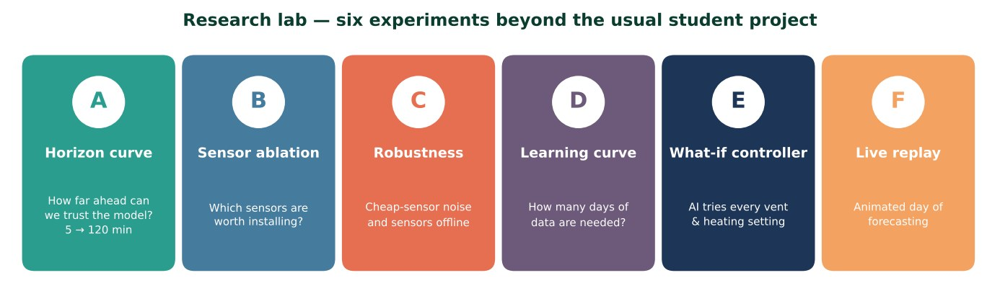

## 21 · Research lab: six experiments beyond the usual project
These experiments answer the practical questions an examiner or a greenhouse owner would ask next. To keep run time short, each uses LightGBM (fast and among the most accurate models here), with the same time-ordered split.

In [31]:
LAB = {}
def quick_lgbm(n=600):
    return lgb.LGBMRegressor(n_estimators=n, learning_rate=0.05, num_leaves=63, subsample=0.8, subsample_freq=1,
                             colsample_bytree=0.8, random_state=SEED, n_jobs=-1, verbose=-1)
def rmse_np(a, b): return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))

### Lab A · How far ahead can we trust the forecast?
One model per horizon from 5 to 120 minutes. Skill against persistence shows where machine learning adds the most value.

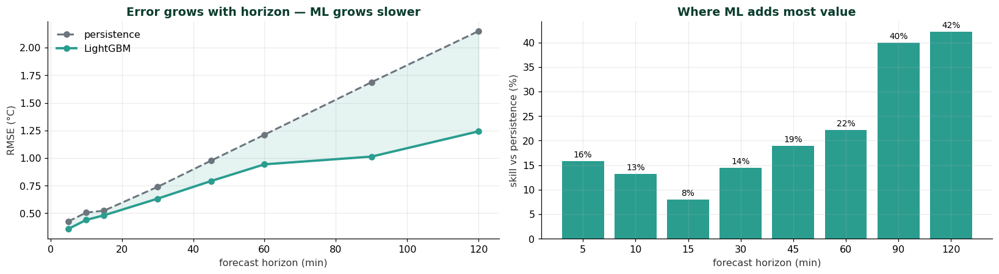

horizon_min,RMSE,persistence_RMSE,R2,skill_pct
5,0.359000,0.426000,0.991000,15.829000
10,0.439000,0.506000,0.986000,13.182000
15,0.481000,0.523000,0.983000,8.040000
30,0.632000,0.739000,0.971000,14.465000
45,0.792000,0.976000,0.954000,18.914000
60,0.943000,1.212000,0.935000,22.154000
90,1.013000,1.687000,0.924000,39.960000
120,1.242000,2.150000,0.886000,42.239000


In [32]:
H_LIST = [5, 10, 15, 30, 45, 60, 90, 120]
rows = []
for h in H_LIST:
    y = data["Tair"].shift(-h // CFG["STEP_MIN"]).reindex(X_all.index)
    d = y - X_all["Tair"]
    mtr, mte = d.loc[idx_tr].notna(), d.loc[idx_te].notna()
    m = quick_lgbm().fit(X_tr[mtr], d.loc[idx_tr][mtr])
    p = X_te["Tair"][mte] + m.predict(X_te[mte]); yt = y.loc[idx_te][mte]
    rows.append(dict(horizon_min=h, RMSE=rmse_np(yt, p), persistence_RMSE=rmse_np(yt, X_te["Tair"][mte]), R2=r2_score(yt, p)))
HZ = pd.DataFrame(rows); HZ["skill_pct"] = 100 * (1 - HZ.RMSE / HZ.persistence_RMSE)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
ax[0].plot(HZ.horizon_min, HZ.persistence_RMSE, "o--", color=C["grey"], lw=2, label="persistence")
ax[0].plot(HZ.horizon_min, HZ.RMSE, "o-", color=C["teal"], lw=2.5, label="LightGBM")
ax[0].fill_between(HZ.horizon_min, HZ.RMSE, HZ.persistence_RMSE, color=C["teal"], alpha=0.12)
ax[0].set_xlabel("forecast horizon (min)"); ax[0].set_ylabel("RMSE (°C)"); ax[0].set_title("Error grows with horizon — ML grows slower"); ax[0].legend()
ax[1].bar(HZ.horizon_min.astype(str), HZ.skill_pct, color=C["teal"]); ax[1].set_xlabel("forecast horizon (min)")
ax[1].set_ylabel("skill vs persistence (%)"); ax[1].set_title("Where ML adds most value")
for i, v in enumerate(HZ.skill_pct): ax[1].text(i, v + 0.8, f"{v:.0f}%", ha="center", fontsize=9)
fig.tight_layout(); save(fig, "20_lab_horizon"); plt.show()
LAB["horizon"] = HZ
display(HZ.round(3).style.hide(axis="index"))

### Lab B · Sensor ablation: which sensors are worth installing?
The model is retrained with sensor groups added one at a time. This tells a farmer on a budget which sensors to buy first.

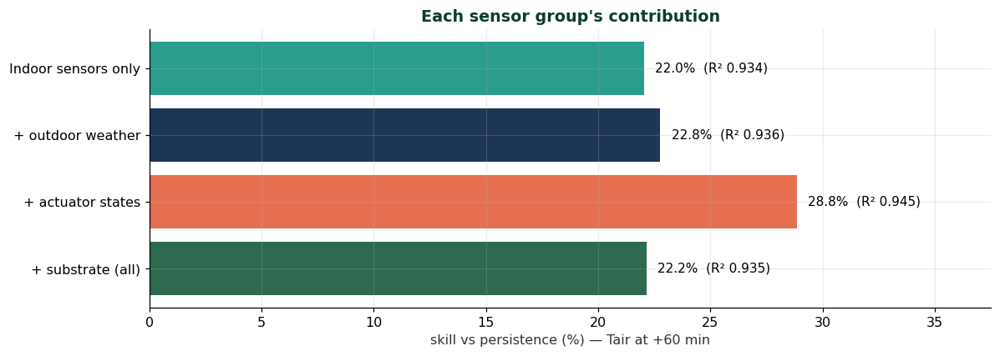

Note: adding 'substrate (all)' LOWERED skill from 28.8% to 22.2%. Those signals behaved differently in the spring test weeks than in winter training, so more sensors is not automatically better.


sensor_set,n_features,RMSE,R2,skill_pct
Indoor sensors only,48,0.945000,0.934000,22.041000
+ outdoor weather,58,0.936000,0.936000,22.754000
+ actuator states,67,0.862000,0.945000,28.848000
+ substrate (all),70,0.943000,0.935000,22.154000


In [33]:
import re
def group_of(f):
    b = re.split(r"_lag|_roll|_diff", f)[0]
    if f in ("Tin_minus_Tout",) or b in OUTDOOR: return "outdoor"
    if b in ACTUATORS: return "actuators"
    if b in SLAB: return "substrate"
    return "indoor"
GROUP = {f: group_of(f) for f in FEATURES}
steps = [("Indoor sensors only", ["indoor"]), ("+ outdoor weather", ["indoor", "outdoor"]),
         ("+ actuator states", ["indoor", "outdoor", "actuators"]), ("+ substrate (all)", ["indoor", "outdoor", "actuators", "substrate"])]
col = "Tair_t+60"; rows = []
for name, gs in steps:
    feats = [f for f in FEATURES if GROUP[f] in gs]
    m = quick_lgbm().fit(X_tr[feats], delta(idx_tr, col))
    p = X_te["Tair"] + m.predict(X_te[feats]); y = Y_all.loc[idx_te, col]
    rows.append(dict(sensor_set=name, n_features=len(feats), RMSE=rmse_np(y, p), R2=r2_score(y, p)))
AB = pd.DataFrame(rows); pers = rmse_np(Y_all.loc[idx_te, col], X_te["Tair"]); AB["skill_pct"] = 100 * (1 - AB.RMSE / pers)
fig, ax = plt.subplots(figsize=(11, 4))
bars = ax.barh(AB.sensor_set, AB.skill_pct, color=[C["teal"], C["blue"], C["orange"], C["green"]])
for b_, v, r2 in zip(bars, AB.skill_pct, AB.R2): ax.text(v + 0.5, b_.get_y() + b_.get_height() / 2, f"{v:.1f}%  (R² {r2:.3f})", va="center", fontsize=10)
ax.invert_yaxis(); ax.set_xlabel("skill vs persistence (%) — Tair at +60 min"); ax.set_title("Each sensor group's contribution")
ax.set_xlim(0, max(AB.skill_pct) * 1.3); fig.tight_layout(); save(fig, "21_lab_sensor_ablation"); plt.show()
LAB["ablation"] = AB
for k in range(1, len(AB)):
    if AB.skill_pct.iloc[k] < AB.skill_pct.iloc[k - 1]:
        print(f"Note: adding '{AB.sensor_set.iloc[k].lstrip('+ ')}' LOWERED skill from {AB.skill_pct.iloc[k-1]:.1f}% to {AB.skill_pct.iloc[k]:.1f}%. "
              "Those signals behaved differently in the spring test weeks than in winter training, so more sensors is not automatically better.")
best_set = AB.loc[AB.skill_pct.idxmax()]
section_banner(f"Best sensor set: {best_set.sensor_set} → {best_set.skill_pct:.1f}% skill (R² {best_set.R2:.3f})", C["teal"])
display(AB.round(3).style.hide(axis="index"))

### Lab C · Robustness: cheap sensors and failures
A low-cost DHT22 reads temperature to about ±0.5 °C and humidity to about ±2 % RH (manufacturer datasheet). The trained model is tested on test data with that noise added to the indoor readings, with double that noise, and with whole sensor groups offline. LightGBM handles missing inputs natively, so the system degrades instead of crashing.

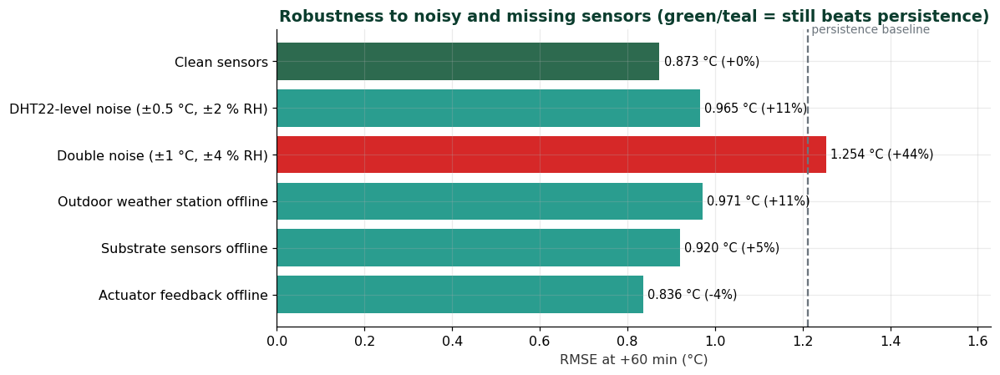

Note: 'Actuator feedback offline' gave a LOWER error (-4%). That sensor group did not help on the test weeks: its relationship with temperature shifted between winter (training) and spring (test).


In [34]:
rng = np.random.default_rng(SEED)
col = "Tair_t+60"; model = FITTED[(col, "LightGBM")]; y = Y_all.loc[idx_te, col]
def eval_on(d_raw, drop=()):
    Xn = make_features(d_raw).reindex(index=idx_te, columns=FEATURES)
    for g in drop:
        Xn.loc[:, [f for f in FEATURES if GROUP[f] == g]] = np.nan
    p = Xn["Tair"].values + model.predict(Xn)            # anchored on the (possibly noisy) reading, as a real gateway would be
    return rmse_np(y, p)
def noisy(k):
    d = data.copy(); d["Tair"] += rng.normal(0, 0.5 * k, len(d)); d["Rhair"] = (d["Rhair"] + rng.normal(0, 2 * k, len(d))).clip(0, 100); return d
scen = [("Clean sensors", eval_on(data)), ("DHT22-level noise (±0.5 °C, ±2 % RH)", eval_on(noisy(1))),
        ("Double noise (±1 °C, ±4 % RH)", eval_on(noisy(2))), ("Outdoor weather station offline", eval_on(data, ["outdoor"])),
        ("Substrate sensors offline", eval_on(data, ["substrate"])), ("Actuator feedback offline", eval_on(data, ["actuators"]))]
RB = pd.DataFrame(scen, columns=["scenario", "RMSE"]); RB["vs_clean_pct"] = 100 * (RB.RMSE / RB.RMSE.iloc[0] - 1)
pers = rmse_np(y, X_te["Tair"])
fig, ax = plt.subplots(figsize=(11, 4.2))
colors = [C["green"]] + [C["teal"] if r < pers else C["red"] for r in RB.RMSE[1:]]
ax.barh(RB.scenario, RB.RMSE, color=colors); ax.axvline(pers, color=C["grey"], ls="--", lw=1.5); ax.invert_yaxis()
ax.text(pers, -0.6, " persistence baseline", color=C["grey"], fontsize=9)
for i, (r, v) in enumerate(zip(RB.RMSE, RB.vs_clean_pct)): ax.text(r + 0.01, i, f"{r:.3f} °C ({v:+.0f}%)", va="center", fontsize=9.5)
ax.set_xlabel("RMSE at +60 min (°C)"); ax.set_title("Robustness to noisy and missing sensors (green/teal = still beats persistence)")
ax.set_xlim(0, max(RB.RMSE.max(), pers) * 1.3); fig.tight_layout(); save(fig, "22_lab_robustness"); plt.show()
LAB["robustness"] = RB
helps_not = RB[(RB.scenario.str.contains("offline")) & (RB.vs_clean_pct < 0)]
for _, r in helps_not.iterrows():
    print(f"Note: '{r.scenario}' gave a LOWER error ({r.vs_clean_pct:+.0f}%). That sensor group did not help on the test weeks: "
          "its relationship with temperature shifted between winter (training) and spring (test).")

### Lab D · Learning curve: how much data does a new greenhouse need?
The model is trained on only the most recent *N* days of the training period and always tested on the same test weeks.

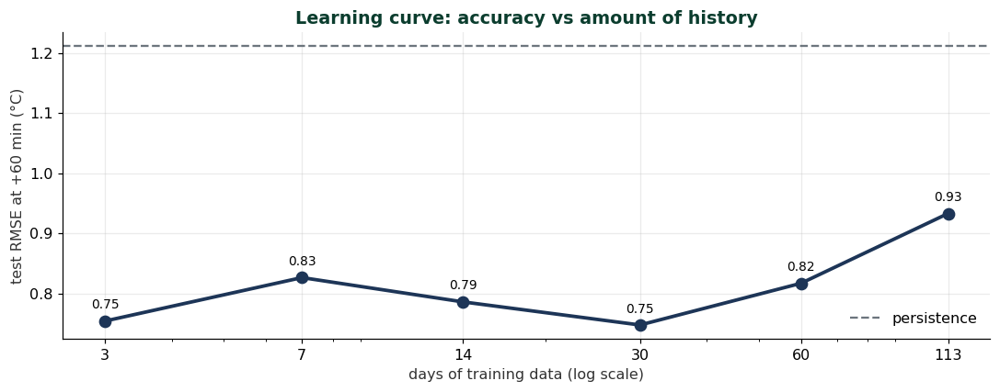

days,samples,RMSE
3,864,0.754000
7,2016,0.826000
14,3958,0.786000
30,8525,0.748000
60,16901,0.817000
113,31861,0.933000


In [35]:
col = "Tair_t+60"; y = Y_all.loc[idx_te, col]; end = idx_tr.max(); rows = []
for days in [3, 7, 14, 30, 60, None]:
    ix = idx_tr if days is None else idx_tr[idx_tr > end - pd.Timedelta(days=days)]
    m = quick_lgbm(400).fit(X_all.loc[ix], delta(ix, col))
    rows.append(dict(days=(idx_tr.max() - idx_tr.min()).days if days is None else days, samples=len(ix),
                     RMSE=rmse_np(y, X_te["Tair"] + m.predict(X_te))))
LC = pd.DataFrame(rows); pers = rmse_np(y, X_te["Tair"])
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(LC.days, LC.RMSE, "o-", color=C["blue"], lw=2.5, ms=8); ax.axhline(pers, color=C["grey"], ls="--", label="persistence")
for d_, r in zip(LC.days, LC.RMSE): ax.annotate(f"{r:.2f}", (d_, r), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=9)
ax.set_xscale("log"); ax.set_xticks(LC.days); ax.set_xticklabels(LC.days); ax.set_xlabel("days of training data (log scale)")
ax.set_ylabel("test RMSE at +60 min (°C)"); ax.set_title("Learning curve: accuracy vs amount of history"); ax.legend()
fig.tight_layout(); save(fig, "23_lab_learning_curve"); plt.show()
LAB["learning_curve"] = LC
display(LC.round(3).style.hide(axis="index"))

### Lab E · AI "what-if" controller
The trained model acts as a fast **digital twin**. For a hot test moment it is asked: *"If the vents were at X % and the heating pipe at Y °C, what would the air temperature be in 30 minutes?"* Every combination is scored, and the controller recommends the gentlest setting that keeps the forecast inside the target band.

*Caution:* the model learned from observational data, where the climate computer's own choices are mixed with the weather. Treat these answers as **decision support**, not proven cause and effect. A physical trial or a greenhouse simulator would be needed to confirm them.

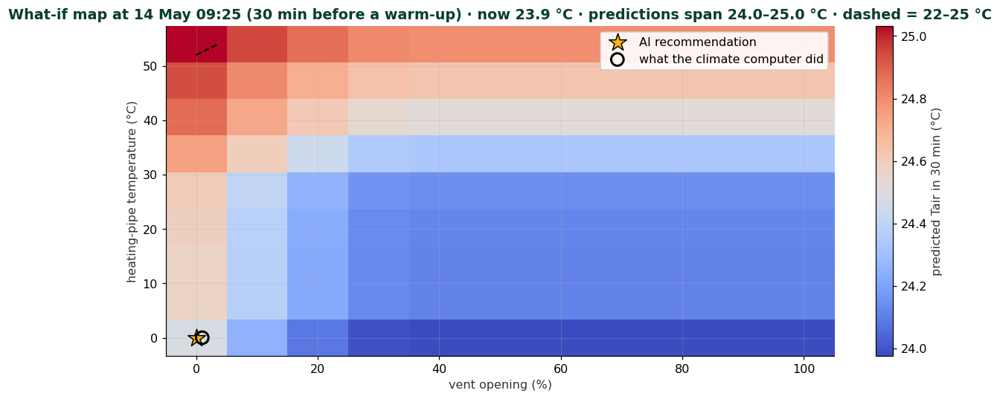

interactive(children=(IntSlider(value=1, description='vent', step=5), IntSlider(value=0, description='pipe', m…

In [36]:
col = "Tair_t+30"; model = FITTED[(col, "LightGBM")]
TARGET_BAND = (CFG["VENT_T"] - 3, CFG["VENT_T"])
# pick the moment 30 min before a typical warm-up (Tair about to cross the vent threshold): that is when proactive control matters
cand = [o - pd.Timedelta(minutes=30) for o in onsets if (o - pd.Timedelta(minutes=30)) in X_te.index]
ts = cand[len(cand) // 2] if cand else idx_te[HOT_STEP]
base_row = X_te.loc[[ts]]
vents = np.arange(0, 101, 10)
pipes = np.linspace(X_tr["PipeLow"].quantile(0.02), X_tr["PipeLow"].quantile(0.98), 9).round(0)
dp = np.diff(pipes).mean()
grid = np.zeros((len(pipes), len(vents)))
for i, pv in enumerate(pipes):
    for j, v in enumerate(vents):
        r = base_row.copy()
        for c_ in ["VentLee", "Ventwind"]:
            if c_ in r: r[c_] = v
        for c_ in ["PipeLow", "PipeGrow"]:
            if c_ in r: r[c_] = pv
        grid[i, j] = r["Tair"].iloc[0] + model.predict(r)[0]
ok = (grid >= TARGET_BAND[0]) & (grid <= TARGET_BAND[1])
effort = (pipes[:, None] - pipes.min()) / np.ptp(pipes) + vents[None, :] / 100 * 0.3     # prefer less heating, then less venting
if ok.any():
    k = np.argmin(np.where(ok, effort, np.inf)); bi, bj = np.unravel_index(k, grid.shape); rec = "inside the target band"
else:
    k = np.argmin(np.abs(grid - np.mean(TARGET_BAND))); bi, bj = np.unravel_index(k, grid.shape); rec = "closest to the target band"
fig, ax = plt.subplots(figsize=(11, 5))
im = ax.imshow(grid, origin="lower", aspect="auto", cmap="coolwarm", extent=[vents[0] - 5, vents[-1] + 5, pipes[0] - dp / 2, pipes[-1] + dp / 2])
cs = ax.contour(vents, pipes, grid, levels=list(TARGET_BAND), colors="black", linewidths=1.4, linestyles="--")
ax.clabel(cs, fmt="%.0f °C", fontsize=9)
ax.scatter([vents[bj]], [pipes[bi]], s=260, marker="*", color=C["yellow"], edgecolor="black", zorder=5, label="AI recommendation")
now_v = base_row[["VentLee", "Ventwind"]].mean(axis=1).iloc[0]; now_p = base_row["PipeLow"].iloc[0]
ax.scatter([now_v], [now_p], s=120, marker="o", facecolor="none", edgecolor="black", lw=2, zorder=5, label="what the climate computer did")
fig.colorbar(im, ax=ax, label="predicted Tair in 30 min (°C)")
ax.set_xlabel("vent opening (%)"); ax.set_ylabel("heating-pipe temperature (°C)"); ax.legend(loc="upper right", framealpha=0.9, frameon=True)
ax.set_title(f"What-if map at {ts:%d %b %H:%M} (30 min before a warm-up) · now {base_row['Tair'].iloc[0]:.1f} °C · "
             f"predictions span {grid.min():.1f}–{grid.max():.1f} °C · dashed = {TARGET_BAND[0]:g}–{TARGET_BAND[1]:g} °C")
fig.tight_layout(); save(fig, "24_lab_whatif"); plt.show()
LAB["whatif"] = dict(time=str(ts), vent=int(vents[bj]), pipe=int(pipes[bi]), predicted=float(grid[bi, bj]), status=rec,
                     actual_30min_later=float(Y_all.loc[ts, col]))
section_banner(f"AI recommendation: vents {vents[bj]} % · heating pipe {pipes[bi]:.0f} °C → predicted {grid[bi, bj]:.1f} °C in 30 min ({rec}) · "
               f"what actually happened with the climate computer's settings: {Y_all.loc[ts, col]:.1f} °C", C["blue"])

try:
    import ipywidgets as widgets
    def try_setting(vent=int(now_v // 10 * 10), pipe=int(now_p)):
        r = base_row.copy(); r[["VentLee", "Ventwind"]] = vent; r[["PipeLow", "PipeGrow"]] = pipe
        print(f"vents {vent} %, pipe {pipe} °C  →  predicted Tair in 30 min: {r['Tair'].iloc[0] + model.predict(r)[0]:.2f} °C")
    widgets.interact(try_setting, vent=widgets.IntSlider(int(now_v), 0, 100, 5),
                     pipe=widgets.IntSlider(int(now_p), int(pipes.min()), int(pipes.max()), 1));
except Exception:
    pass

### Lab F · Live replay: a day of forecasting, animated
Press ▶ to watch the system work through the hottest test day. The black line is what happened; the orange points are the forecasts made at that moment; the bar shows the action it would take.

In [37]:
from matplotlib import animation
plt.rcParams["animation.embed_limit"] = 60
day = pd.Timestamp(idx_te[HOT_STEP]).normalize()
frames = [t for t in idx_te if day <= t < day + pd.Timedelta(days=1)][::3]          # every 15 min
pT30 = PRED["test"][("Tair_t+30", BEST.loc["Tair_t+30", "model"])]; pT60 = PRED["test"][("Tair_t+60", BEST.loc["Tair_t+60", "model"])]
lo60, hi60 = INTERVALS["Tair_t+60"]
dd = data.loc[day: day + pd.Timedelta(days=1), "Tair"]
fig, ax = plt.subplots(figsize=(11, 4.2), dpi=80)
ax.set_xlim(day, day + pd.Timedelta(days=1)); ax.set_ylim(dd.min() - 1.5, dd.max() + 1.5)
ax.axhline(CFG["VENT_T"], color=C["red"], ls=":", lw=1.2); ax.axhline(CFG["HEAT_T"], color=C["blue"], ls=":", lw=1.2)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M")); ax.set_ylabel("°C")
past, = ax.plot([], [], color="black", lw=2); fc, = ax.plot([], [], "o-", color=C["orange"], lw=2, ms=7)
band = ax.fill_between([], [], [], color=C["orange"], alpha=0.2); now_line = ax.axvline(day, color=C["grey"], lw=1)
txt = ax.text(0.01, 0.95, "", transform=ax.transAxes, fontsize=12, weight="bold", va="top")
def draw(t):
    global band
    hist = dd.loc[:t]; past.set_data(hist.index, hist.values); now_line.set_xdata([t, t])
    xs = [t, t + pd.Timedelta(minutes=30), t + pd.Timedelta(minutes=60)]
    fc.set_data(xs, [hist.iloc[-1], pT30.get(t, np.nan), pT60.get(t, np.nan)])
    band.remove(); band = ax.fill_between([xs[0], xs[2]], [hist.iloc[-1], lo60.get(t, np.nan)], [hist.iloc[-1], hi60.get(t, np.nan)], color=C["orange"], alpha=0.2)
    act = "VENTILATE" if pT30.get(t, 0) > CFG["VENT_T"] else ("HEAT" if pT30.get(t, 99) < CFG["HEAT_T"] else "HOLD")
    txt.set_text(f"{t:%H:%M}  ·  now {hist.iloc[-1]:.1f} °C  →  +60 min {pT60.get(t, np.nan):.1f} °C  ·  action: {act}")
    txt.set_color({"VENTILATE": C["teal"], "HEAT": C["orange"], "HOLD": C["green"]}[act]); return past, fc, txt
ax.set_title(f"Live forecasting replay — {day:%d %b %Y}")
anim = animation.FuncAnimation(fig, draw, frames=frames, interval=120, blit=False)
try:
    anim.save(os.path.join(FIG_DIR, "25_live_replay.gif"), writer=animation.PillowWriter(fps=8))
except Exception as e:
    print("GIF not saved:", e)
plt.close(fig)
HTML(anim.to_jshtml())

## 22 · Generalisation: an unseen greenhouse (Option B data)
Train on all other compartments and test on the held-out one. This shows whether the model transfers to a greenhouse run by a different control strategy. It is skipped automatically with the single-compartment data.

In [38]:
if len(TEAMS) >= 3:
    team_data = {}
    for t in TEAMS:
        d = clean(load_team(t))
        if not set(INDOOR).issubset(d.columns): continue
        Xt, Yt = make_features(d), make_targets(d); m = Xt.notna().all(axis=1) & Yt.notna().all(axis=1)
        team_data[t] = (Xt[m].reindex(columns=FEATURES), Yt[m])
    rows = []
    for held in team_data:
        Xa = pd.concat([team_data[t][0] for t in team_data if t != held]); Ya = pd.concat([team_data[t][1] for t in team_data if t != held])
        Xh, Yh = team_data[held]
        mdl = lgb.LGBMRegressor(n_estimators=600, learning_rate=0.05, num_leaves=63, random_state=SEED, verbose=-1).fit(Xa, Ya["Tair_t+60"] - Xa["Tair"])
        p = Xh["Tair"].values + mdl.predict(Xh); y = Yh["Tair_t+60"].values
        rows.append(dict(held_out=held, R2=r2_score(y, p), RMSE=np.sqrt(mean_squared_error(y, p)),
                         persistence_RMSE=np.sqrt(mean_squared_error(y, Xh["Tair"]))))
    LOCO = pd.DataFrame(rows); LOCO["skill_pct"] = 100 * (1 - LOCO.RMSE / LOCO.persistence_RMSE)
    LOCO.to_csv(os.path.join(CFG["OUT_DIR"], "unseen_greenhouse_test.csv"), index=False)
    display(LOCO.round(3).style.hide(axis="index").bar(subset=["skill_pct"], color="#95d5b2"))
else:
    LOCO = None
    section_banner(f"Only {len(TEAMS)} compartment loaded — switch to Option B (Section 3) to run this test", C["grey"])

## 23 · Save models, figures and results

In [39]:
import joblib, shutil
mdir = os.path.join(CFG["OUT_DIR"], "models"); os.makedirs(mdir, exist_ok=True)
saved = set()
for (c, m), model in FITTED.items():
    if id(model) in saved: continue
    saved.add(id(model)); name = f"{c}_{m}".replace("+", "plus")
    if m in ("LSTM", "GRU"): model.save(os.path.join(mdir, f"{tgt_of(c)}_{m}.keras"))
    else: joblib.dump(model, os.path.join(mdir, f"{name}.joblib"))
joblib.dump(SCALER, os.path.join(mdir, "sequence_scaler.joblib"))
json.dump({"features": FEATURES, "targets": TARGET_COLS, "config": CFG, "tuned_params": TUNED_PARAMS,
           "ensemble_members": ENSEMBLE_MEMBERS, "best_models": BEST["model"].to_dict(), "roc_auc_ventilate": ROC_AUC,
           "lead_time_median_min": float(LEADS.median()) if len(LEADS) else None, "lead_time_events": int(len(LEADS)),
           "interval_conformal_offsets": CQR_Q, "lab_whatif": LAB.get("whatif")},
          open(os.path.join(CFG["OUT_DIR"], "model_card.json"), "w"), indent=2, default=str)
CONTROL.to_csv(os.path.join(CFG["OUT_DIR"], "control_results.csv"), index=False)
COVERAGE.to_csv(os.path.join(CFG["OUT_DIR"], "interval_coverage.csv"), index=False)

## 24 · Auto-generated results summary
Written from this run's own numbers. Paste it into your report or slides and edit as needed.

In [40]:
b = BEST
vent = CONTROL[(CONTROL.action == "VENTILATE")].set_index("controller")["F1"]
lines = [f"# Results summary — Smart Greenhouse Automation System",
         f"*Compartment {CFG['TEAM']}, AGC 2nd edition · test period {idx_te.min():%d %b} – {idx_te.max():%d %b %Y} · {len(idx_te):,} five-minute steps*", "",
         "| Target | Best model | Accuracy | Within tolerance | R² | RMSE | MAE | Skill vs persistence |", "|---|---|---|---|---|---|---|---|"]
for c in TARGET_COLS:
    lines.append(f"| {c} | {b.loc[c,'model']} | {b.loc[c,'accuracy']:.2f}% | {b.loc[c,'within_tol']:.1f}% (±{TOL[tgt_of(c)]:g}) | {b.loc[c,'R2']:.3f} | {b.loc[c,'RMSE']:.2f} {UNIT[tgt_of(c)]} | {b.loc[c,'MAE']:.2f} | {b.loc[c,'skill_pct']:+.1f}% |")
lines += ["",
          f"- **Uncertainty:** after conformal calibration, the 80 % intervals contained the true value {COVERAGE.calibrated_coverage_pct.min():.0f}–{COVERAGE.calibrated_coverage_pct.max():.0f} % of the time (raw quantile bands: {COVERAGE.raw_coverage_pct.min():.0f}–{COVERAGE.raw_coverage_pct.max():.0f} %).",
          f"- **Decision accuracy:** ventilation commands were correct {100*CONTROL[(CONTROL.action=='VENTILATE')&(CONTROL.controller=='Proactive (ML)')].accuracy.iloc[0]:.1f}% of the time with forecasts.",
          f"- **ROC-AUC (ventilate):** {ROC_AUC['Proactive (ML forecast)']:.3f} with forecasts vs {ROC_AUC['Reactive (current value)']:.3f} with current readings.",
          f"- **Control:** ventilation decisions reached F1 {vent.get('Proactive (ML)', np.nan):.3f} with forecasts vs {vent.get('Reactive (thermostat)', np.nan):.3f} with a reactive thermostat."]
if len(LEADS):
    lines.append(f"- **Early warning:** median {LEADS.median():.0f} min before the {CFG['VENT_T']:g} °C threshold was crossed ({len(LEADS)} events).")
lines.append(f"- **Explainability:** the strongest drivers of the 60-min temperature forecast were {', '.join(imp.index[:3])}.")
if "horizon" in LAB:
    hz = LAB["horizon"]; best_h = hz.loc[hz.skill_pct.idxmax()]
    lines.append(f"- **Horizon (Lab A):** ML skill over persistence peaks at {best_h.skill_pct:.0f}% for the {int(best_h.horizon_min)}-min forecast.")
if "ablation" in LAB:
    ab = LAB["ablation"]
    bs = ab.loc[ab.skill_pct.idxmax()]
    lines.append(f"- **Sensors (Lab B):** indoor sensors alone give {ab.skill_pct.iloc[0]:.1f}% skill; the best set ({bs.sensor_set.lstrip('+ ')}) gives {bs.skill_pct:.1f}%, and all sensors {ab.skill_pct.iloc[-1]:.1f}%.")
if "robustness" in LAB:
    rb = LAB["robustness"]
    lines.append(f"- **Robustness (Lab C):** DHT22-level sensor noise changes 60-min RMSE by {rb.vs_clean_pct.iloc[1]:+.0f}%; with the outdoor station offline it changes by {rb.vs_clean_pct.iloc[3]:+.0f}%.")
if "whatif" in LAB:
    w = LAB["whatif"]
    lines.append(f"- **What-if controller (Lab E):** at {w['time'][5:16]} it recommended vents {w['vent']} % and pipe {w['pipe']} °C (predicted {w['predicted']:.1f} °C; actual with the real settings {w['actual_30min_later']:.1f} °C).")
if "learning_curve" in LAB:
    lc = LAB["learning_curve"]; pers_ = rmse_np(Y_all.loc[idx_te, 'Tair_t+60'], X_te['Tair']); beat = lc[lc.RMSE < pers_]
    if len(beat): lines.append(f"- **Data needed (Lab D):** {int(beat.days.min())} days of history already beat the persistence baseline.")
if LOCO is not None:
    lines.append(f"- **Unseen greenhouse:** mean R² {LOCO.R2.mean():.3f} across {len(LOCO)} held-out compartments.")
lines += ["", "**Limitations:** one season (Dec 2019 – May 2020), one crop (cherry tomato), a high-tech Dutch glasshouse; "
          "published scores from other datasets are not directly comparable."]
REPORT = "\n".join(lines)
open(os.path.join(CFG["OUT_DIR"], "RESULTS_SUMMARY.md"), "w").write(REPORT)
display(Markdown(REPORT))

shutil.make_archive("smart_greenhouse_outputs", "zip", CFG["OUT_DIR"])
section_banner(f"Done in {(time.time()-NOTEBOOK_START)/60:.1f} min · {len(os.listdir(FIG_DIR))} figures, models and reports → smart_greenhouse_outputs.zip", C["green"])
try:
    from google.colab import files; files.download("smart_greenhouse_outputs.zip")
except Exception:
    pass

# Results summary — Smart Greenhouse Automation System
*Compartment AICU, AGC 2nd edition · test period 02 May – 26 May 2020 · 6,828 five-minute steps*

| Target | Best model | Accuracy | Within tolerance | R² | RMSE | MAE | Skill vs persistence |
|---|---|---|---|---|---|---|---|
| Tair_t+30 | RandomForest | 98.25% | 91.1% (±1) | 0.975 | 0.59 °C | 0.41 | +20.5% |
| Tair_t+60 | RandomForest | 97.41% | 83.5% (±1) | 0.954 | 0.79 °C | 0.60 | +35.0% |
| Rhair_t+30 | LightGBM | 95.99% | 83.9% (±5) | 0.869 | 4.15 % RH | 2.70 | +0.3% |
| Rhair_t+60 | LightGBM-tuned | 93.82% | 70.7% (±5) | 0.730 | 5.94 % RH | 4.17 | +2.3% |

- **Uncertainty:** after conformal calibration, the 80 % intervals contained the true value 67–79 % of the time (raw quantile bands: 55–64 %).
- **Decision accuracy:** ventilation commands were correct 93.7% of the time with forecasts.
- **ROC-AUC (ventilate):** 0.985 with forecasts vs 0.973 with current readings.
- **Control:** ventilation decisions reached F1 0.929 with forecasts vs 0.908 with a reactive thermostat.
- **Early warning:** median 15 min before the 25 °C threshold was crossed (25 events).
- **Explainability:** the strongest drivers of the 60-min temperature forecast were hour_sin, PipeLow, hour_cos.
- **Horizon (Lab A):** ML skill over persistence peaks at 42% for the 120-min forecast.
- **Sensors (Lab B):** indoor sensors alone give 22.0% skill; the best set (actuator states) gives 28.8%, and all sensors 22.2%.
- **Robustness (Lab C):** DHT22-level sensor noise changes 60-min RMSE by +11%; with the outdoor station offline it changes by +11%.
- **What-if controller (Lab E):** at 05-14 09:25 it recommended vents 0 % and pipe 0 °C (predicted 24.5 °C; actual with the real settings 25.2 °C).
- **Data needed (Lab D):** 3 days of history already beat the persistence baseline.

**Limitations:** one season (Dec 2019 – May 2020), one crop (cherry tomato), a high-tech Dutch glasshouse; published scores from other datasets are not directly comparable.

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 25 · References
1. I. Hindi, A. Alsharkawi, M. Al-Ajlouni and B. Qarallah, "Enhancing autonomous agriculture control systems in greenhouses for sustainable resource usage using deep learning techniques," *PLoS ONE*, vol. 21, no. 3, e0344946, 2026. doi:10.1371/journal.pone.0344946
2. S. Hemming, F. de Zwart, A. Elings, A. Petropoulou and I. Righini, "Cherry tomato production in intelligent greenhouses—Sensors and AI for control of climate, irrigation, crop yield, and quality," *Sensors*, vol. 20, no. 22, 6430, 2020. doi:10.3390/s20226430
3. S. Hemming, H. F. de Zwart, A. Elings, A. Petropoulou and I. Righini, "Autonomous Greenhouse Challenge, Second Edition (2019)," 4TU.ResearchData, 2020. doi:10.4121/uuid:88d22c60-21b3-4ea8-90db-20249a5be2a7
4. Y.-J. Jeon *et al.*, "Machine learning-powered forecasting of climate conditions in smart greenhouse containing netted melons," *Agronomy*, vol. 14, no. 5, 1070, 2024. doi:10.3390/agronomy14051070
5. J. M. Esparza-Gómez *et al.*, "Long short-term memory recurrent neural network and extreme gradient boosting algorithms applied in a greenhouse's internal temperature prediction," *Applied Sciences*, vol. 13, no. 22, 12341, 2023. doi:10.3390/app132212341
6. M. J. Bashir, S. Henna and E. Furey, "Explainable AI for smart greenhouse control: Interpretability of Temporal Fusion Transformer in the Internet of Robotic Things," arXiv:2512.11852, 2025.
7. S. M. Lundberg and S.-I. Lee, "A unified approach to interpreting model predictions," *NeurIPS*, 2017. (SHAP)
8. Y. Romano, E. Patterson and E. Candès, "Conformalized quantile regression," *NeurIPS*, 2019.
9. T. Akiba *et al.*, "Optuna: A next-generation hyperparameter optimization framework," *KDD*, 2019.